This notebook is for the WIP paper tentatively titled Response Topography Modulates Response-Withholding Performance in Mice by Daniels et al (in prep).  
*Note: A draft of this paper is not yet available.*   
*Note: Some of this code is back from when I first transitioned from Matlab to Python; thus best practices are not always adhered too; I apologize in advance*

The goal of this study was to **determine the ideal parameters for training mice in a response withholding task under varying levels of motivation**. 
1. To that end, mice were divided into two different groups: initiation/first response as nose-poke (NP) or  lever-press. (LP) 
2. Both groups of mice were then trained in sequence:  differential-reinforcement-of-low rates (DRL) and then a fixed-minimum interval (FMI) schedule of reinforcement. 
3. In each schedule two intervals were explored: 3 s and 6 s; along with two levels of food deprivation. 
4. Once training stabilized in each interval mice were given a pre-feeding challenge (1 hour of food access immediately prior to the experimental session). 

The following data were collected:
1. Latencies: the time to the first response 
2. Inter-response interval (IRT): the time between the first response and the second


Data were originally processed in Matlab (for historical reasons). Rather than repeat such processing, the .mat files and .m files can be found in the Github for this project. The remainder of the processing and analysis needed will be conducted in this Jupyter Notebook unless otherwise specified. 

Specifically,
1. Latencies will be analyzed via an empirical analysis. 
2. IRTs will be analyzed by fitting the Temporal Regulation model (TR: see Watterson et al., 2015) and an extended version of the TR model, which I refer to as TRe. 

Briefly, the TR model assumes that mice fluctuate in and out of two engagement states and that there is a timing state whose IRTs can be described by a gamma distribution and a non-timing state whose IRTs can be described by an exponential distribution. Alternatively, the TRe model assumes that mice fluctuate in and out of three engagement states: the timing state, a burst responding state, and a lapse state. Whereas the timing state can be described as before; the burst responding and lapse states are both described by exponential distributions but with different means. The mean of the burst responding state must be shorter than the mean of the lapse responding state. 

Without belaboring any points or giving away any details crucial for the analysis, let's pull in the packages we will need. 

In [45]:
import sys
import numpy as np
np.set_printoptions(threshold=sys.maxsize)
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io as spio
from scipy.stats import gamma
from scipy.stats import expon
import os
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import pingouin as pg
import re

First we will import the database in storing all IRTs from the experiment and parameter estimates following TR model fitting.

In [46]:
location = "E:\\Dropbox\\2 All of Carter's Stuff\\Carter Local\\ASU Research Projects\\Mutant Mice Projects\\Topography Project\\New Analysis (based on Watterson et al. 2015)\\IRTs_TRmodel1.mat"
matlab_database = spio.loadmat(location, squeeze_me = True)
matlab_names = spio.whosmat(location)
for names in matlab_names:
    print(names)

FileNotFoundError: [Errno 2] No such file or directory: "E:\\Dropbox\\2 All of Carter's Stuff\\Carter Local\\ASU Research Projects\\Mutant Mice Projects\\Topography Project\\New Analysis (based on Watterson et al. 2015)\\IRTs_TRmodel1.mat"

As you can see, this matlab database contains a lot of information. For our first analysis, which is a visualization of model fit we need (1) IRTs for each condition and (2) parameter estimates in each condition. 

IRTs can be found in variables titled Schedule_expX?_PF where Schedule = DRL or FMI X = 1 or 2 and the baseline condition has nothing else but the pre-feeding conditions has _PF.

Parameter estimates can be found in pcollector_Schedule_expX where Schedule and X are as in above for the baseline condition and parameter estimates for the pre-feeding condition are as follows pcollector_Schedule_expX?_PF.

Let's focusing on constructing obtained probability functions. We will start with DRL and move our away through the waiting requirements,schedules, and feeding conditions until we finish with FMI 6-s.

Note that because we will do some model selection we are going to gather counts of the amount of data. 

In [47]:
##DRL Data. Note that due to a chamber malfunction subject 1 does not have reliable pre-feeding for 6-s
#Baseline
data_counts = np.zeros([2,16])
E1_DRL_B = matlab_database['DRL_exp1'] #Note that the last column indicates the waiting requirement
E1_DRL_B3 = E1_DRL_B[E1_DRL_B[:,-1]==3,2:-1] #Select data only for 3 s condition, dropping the waiting requirement
databins = np.linspace(0,15,31)
E1_DRL_B_3hist = np.zeros((databins.shape[0]-1,16)) 
for i in range(0,16): 
    data = E1_DRL_B3[:,i][~np.isnan(E1_DRL_B3[:,i])]
    data_counts[0,i] = data_counts[0,i] + np.count_nonzero(E1_DRL_B3[:,i][~np.isnan(E1_DRL_B3[:,i])])
    output = np.histogram(data,bins=databins, density=False)
    E1_DRL_B_3hist[:,i] = np.divide(output[:][0],np.sum(output[:][0]))
    
E1_DRL_B6 = E1_DRL_B[E1_DRL_B[:,-1]==6,2:-1] #Select data only for 6 s condition, dropping needless columns
E1_DRL_B_6hist = np.zeros((databins.shape[0]-1,16)) #Empty array
for i in range(0,15):
    data = E1_DRL_B6[:,i][~np.isnan(E1_DRL_B6[:,i])]
    data_counts[0,i] = data_counts[0,i] + np.count_nonzero(E1_DRL_B6[:,i][~np.isnan(E1_DRL_B6[:,i])])
    output = np.histogram(data,bins=databins, density=False)
    E1_DRL_B_6hist[:,i] = np.divide(output[:][0],np.sum(output[:][0]))
    
#Pre-feeding
E1_DRL_PF = matlab_database['DRL_exp1_PF'] #Note that the last column indicates the waiting requirement
E1_DRL_PF3 = E1_DRL_PF[E1_DRL_PF[:,-1]==3,2:-1] #Select data only for 3 s condition, dropping the waiting requirement
E1_DRL_PF_3hist = np.zeros((databins.shape[0]-1,16)) 
for i in range(0,16): 
    data = E1_DRL_PF3[:,i][~np.isnan(E1_DRL_PF3[:,i])]
    data_counts[0,i] = data_counts[0,i] + np.count_nonzero(E1_DRL_PF3[:,i][~np.isnan(E1_DRL_PF3[:,i])])
    output = np.histogram(data,bins=databins, density=False)
    E1_DRL_PF_3hist[:,i] = np.divide(output[:][0],np.sum(output[:][0]))
    
E1_DRL_PF6 = E1_DRL_PF[E1_DRL_PF[:,-1]==6,2:-1] #Select data only for 6 s condition, dropping needless columns
E1_DRL_PF_6hist = np.zeros((databins.shape[0]-1,16)) #Empty array
for i in range(0,15):
    data = E1_DRL_PF6[:,i][~np.isnan(E1_DRL_PF6[:,i])]
    data_counts[0,i] = data_counts[0,i] + np.count_nonzero(E1_DRL_PF6[:,i][~np.isnan(E1_DRL_PF6[:,i])])
    output = np.histogram(data,bins=databins, density=False)
    E1_DRL_PF_6hist[:,i] = np.divide(output[:][0],np.sum(output[:][0]))
    
#FMI Data. Note that Subject 16 died during the FMI condition and thus has no data
#Baseline
E1_FMI_B = matlab_database['FMI_exp1'] #Note that the last column indicates the waiting requirement
E1_FMI_B3 = E1_FMI_B[E1_FMI_B[:,-1]==3,2:-1] #Select data only for 3 s condition, dropping needless columns
E1_FMI_B_3hist = np.zeros((databins.shape[0]-1,15)) 
for i in range(0,15): 
    data = E1_FMI_B3[:,i][~np.isnan(E1_FMI_B3[:,i])]
    data_counts[1,i] = data_counts[1,i] + np.count_nonzero(E1_FMI_B3[:,i][~np.isnan(E1_FMI_B3[:,i])])
    output = np.histogram(data,bins=databins, density=False)
    E1_FMI_B_3hist[:,i] = np.divide(output[:][0],np.sum(output[:][0]))
    
E1_FMI_B6 = E1_FMI_B[E1_FMI_B[:,-1]==6,2:-1] #Select data only for 6 s condition, dropping needless columns
E1_FMI_B_6hist = np.zeros((databins.shape[0]-1,15)) #Empty array
for i in range(0,15):
    data = E1_FMI_B6[:,i][~np.isnan(E1_FMI_B6[:,i])]
    data_counts[1,i] = data_counts[1,i] + np.count_nonzero(E1_FMI_B6[:,i][~np.isnan(E1_FMI_B6[:,i])])
    output = np.histogram(data,bins=databins, density=False)
    E1_FMI_B_6hist[:,i] = np.divide(output[:][0],np.sum(output[:][0]))
    
#Pre-feeding
E1_FMI_PF = matlab_database['FMI_exp1_PF'] #Note that the last column indicates the waiting requirement
E1_FMI_PF3 = E1_FMI_PF[E1_FMI_PF[:,-1]==3,2:-1] #Select data only for 3 s condition, dropping needless columns
E1_FMI_PF_3hist = np.zeros((databins.shape[0]-1,15)) 
for i in range(0,15): 
    data = E1_FMI_PF3[:,i][~np.isnan(E1_FMI_PF3[:,i])]
    data_counts[1,i] = data_counts[1,i] + np.count_nonzero(E1_FMI_PF3[:,i][~np.isnan(E1_FMI_PF3[:,i])])
    output = np.histogram(data,bins=databins, density=False)
    E1_FMI_PF_3hist[:,i] = np.divide(output[:][0],np.sum(output[:][0]))
    
E1_FMI_PF6 = E1_FMI_PF[E1_FMI_PF[:,-1]==6,2:-1] #Select data only for 6 s condition, dropping needless columns
E1_FMI_PF_6hist = np.zeros((databins.shape[0]-1,15)) #Empty array
for i in range(0,15):
    data = E1_FMI_PF6[:,i][~np.isnan(E1_FMI_PF6[:,i])]
    data_counts[1,i] = data_counts[1,i] + np.count_nonzero(E1_FMI_PF6[:,i][~np.isnan(E1_FMI_PF6[:,i])])
    output = np.histogram(data,bins=databins, density=False)
    E1_FMI_PF_6hist[:,i] = np.divide(output[:][0],np.sum(output[:][0]))


Now that the data has been sorted we can confirm the pdfs of each animal in the next cell. Note that subject 16 was dropped from analysis because the subject died before the experiment could be completed. 

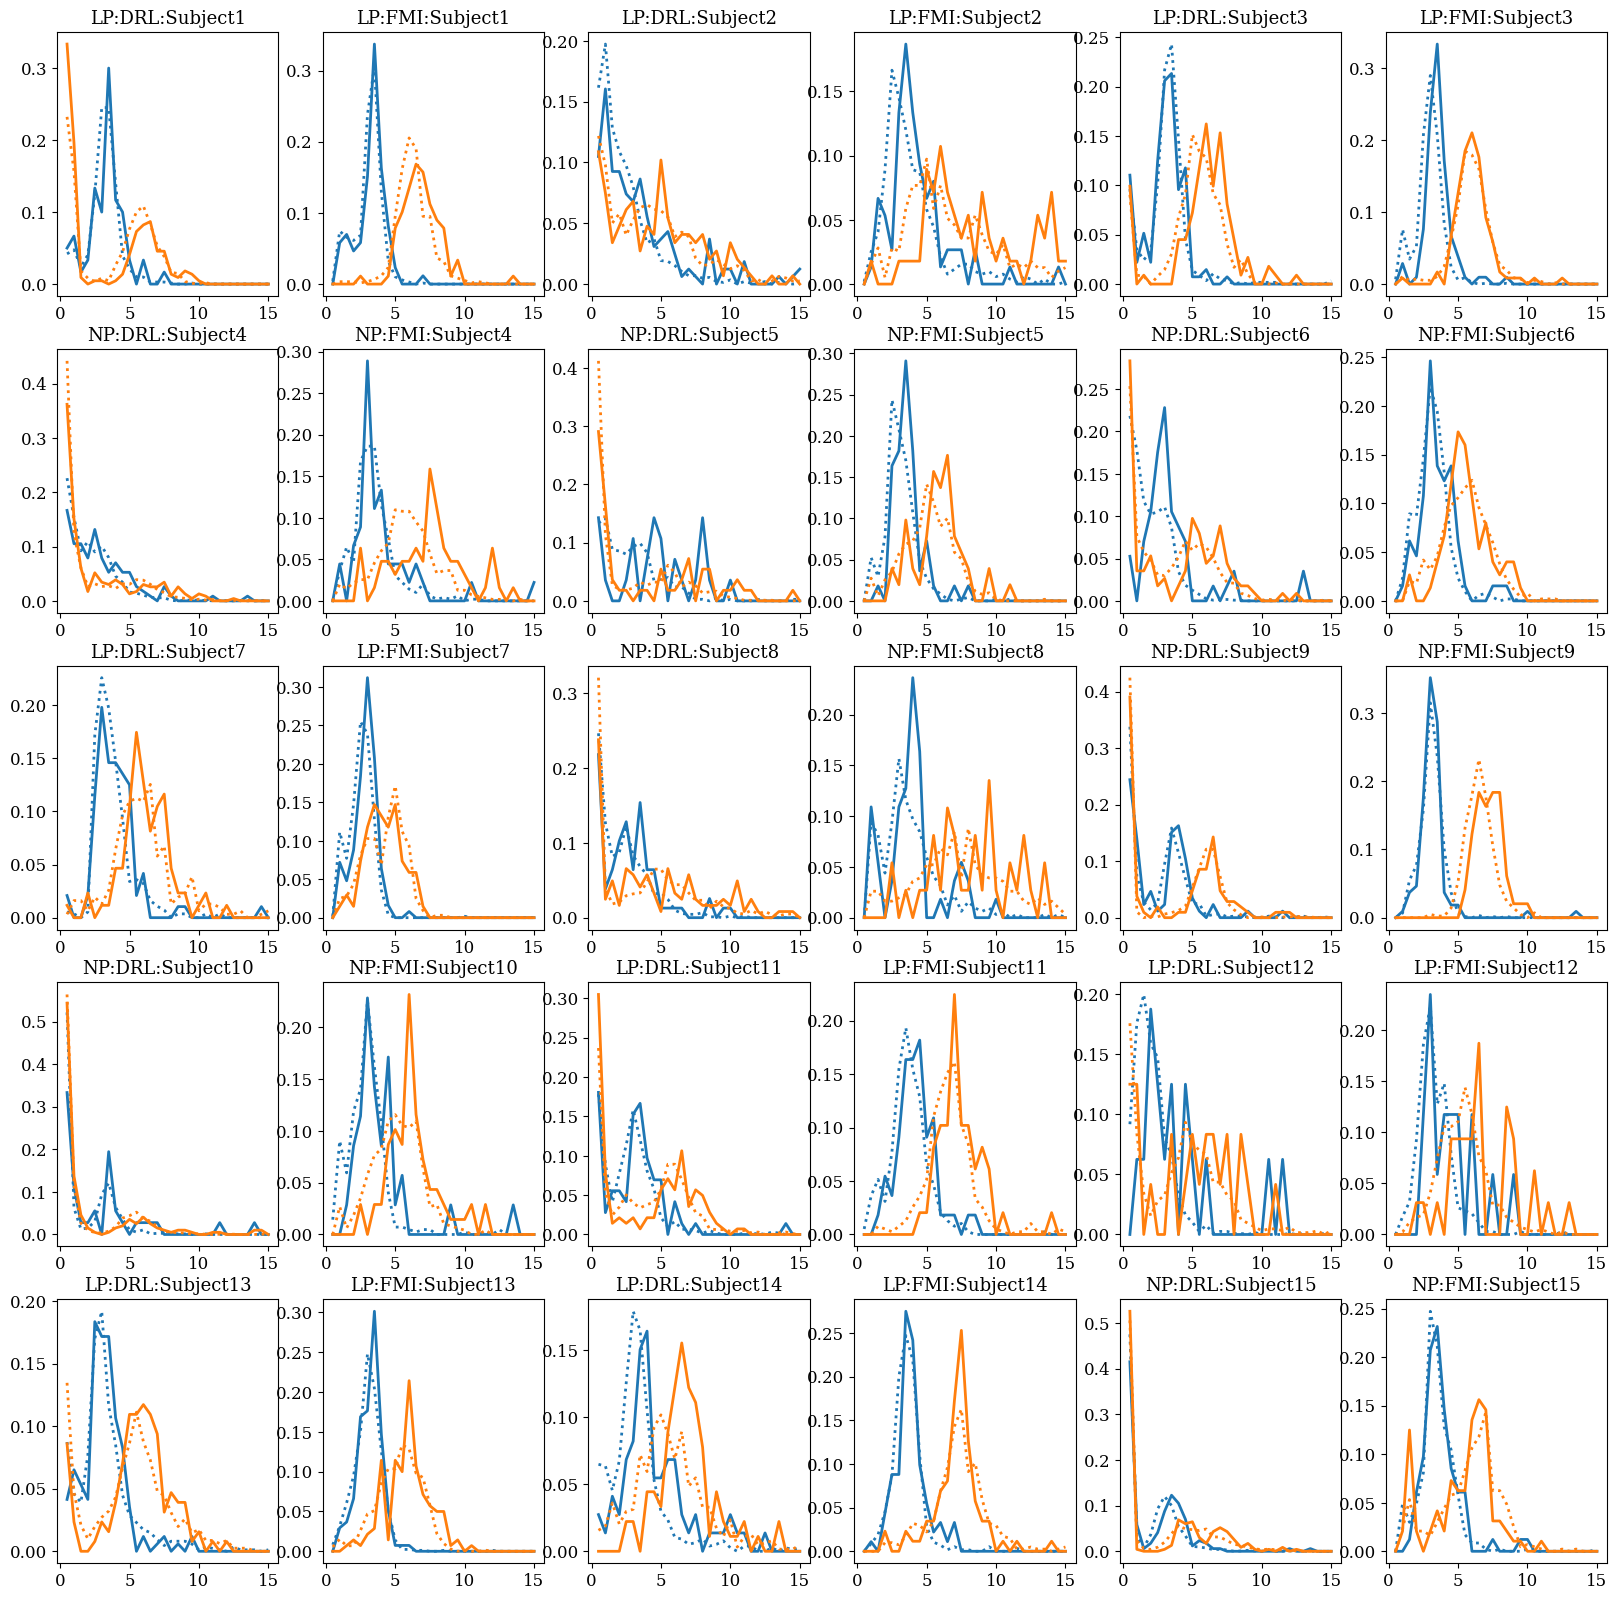

In [48]:
#Column wise group assignment mirroring the data matrices in matlab (setting this up here because it will need to be used throughout the analysis)
colwiseGA = ['LP','LP','LP','NP','NP','NP','LP','NP','NP','NP','LP','LP','LP','LP','NP','NP']
LPindices = [i for i, x in enumerate(colwiseGA) if x == "LP"]
NPindices = [i for i, x in enumerate(colwiseGA) if x == "NP"]
LPindices_mod = np.delete(LPindices,1)
NPindices = np.delete(NPindices,-1)

plt.rc('font', family='serif')
plt.rc('xtick', labelsize='large')
plt.rc('ytick', labelsize='large')
fig1 = plt.figure(figsize=(20,24))
k = 0
for i in range(0,15):
    plt.subplot(6,6,k+1)
    plt.plot(databins[1:len(databins)],E1_DRL_B_3hist[:,i], color = "tab:blue", linestyle = ":", linewidth = 2)
    plt.plot(databins[1:len(databins)],E1_DRL_PF_3hist[:,i], color = "tab:blue", linestyle = "-", linewidth = 2)
    plt.plot(databins[1:len(databins)],E1_DRL_B_6hist[:,i], color = "tab:orange", linestyle = ":", linewidth = 2)
    plt.plot(databins[1:len(databins)],E1_DRL_PF_6hist[:,i], color = "tab:orange", linestyle = "-", linewidth = 2)
    plt.title(colwiseGA[i]+":DRL:Subject"+str(i+1))
    plt.subplot(6,6,k+2)
    plt.plot(databins[1:len(databins)],E1_FMI_B_3hist[:,i], color = "tab:blue", linestyle = ":", linewidth = 2)
    plt.plot(databins[1:len(databins)],E1_FMI_PF_3hist[:,i], color = "tab:blue", linestyle = "-", linewidth = 2)
    plt.plot(databins[1:len(databins)],E1_FMI_B_6hist[:,i], color = "tab:orange", linestyle = ":", linewidth = 2)
    plt.plot(databins[1:len(databins)],E1_FMI_PF_6hist[:,i], color = "tab:orange", linestyle = "-", linewidth = 2)
    plt.title(colwiseGA[i]+":FMI:Subject"+str(i+1))
    k = k + 2




First we need to determine which version of the TR model we should use. The TR model offerred by Watterson et al. (2015) suggest there are only two states: a timing state and a non-timing state. In our expanded TR model (TRe) assumes there are three states: a timing state, a burst-response state, and a lapsed state. 

Thus, we will extract the loglikelihood of our two models across waiting requirements and feeding regimen and select the best model within each schedule. In the approach taken here we want to choose for each schedule (DRL and FMI) within each group of mice the best fitting model that captures behavior under each interval (3 and 6 s) as well as before and during the pre-feeding challenge. 

In [49]:
#Number of free parameters
TR_params = 4 * 4 #num of params in model * number of conditions
TRe_params = 6 * 4 #num of params in model * number of conditions; note this will get multiplied by num of animals when AICc is calculcated

#Amount of data
DRLdata = data_counts[0,:]
FMIdata = data_counts[1,:]

#Preallocate matrix for loglikelihood data
DRL_e1_LLout_TR = np.empty([16,5])
DRL_e1_LLout_TRe = np.empty([16,5])
FMI_e1_LLout_TR = np.empty([16,5])
FMI_e1_LLout_TRe = np.empty([16,5])
#Preallocation matrix for AICc calculation
AICc = np.zeros([2,2])

#Grab Loglikelihood data
DRL_e1_LLout_TR[:,0] = matlab_database['LLcollector_DRL_e1_B3']
DRL_e1_LLout_TR[:,1] = matlab_database['LLcollector_DRL_e1_B6']
DRL_e1_LLout_TR[:,2] = matlab_database['LLcollector_DRL_e1_PF3']
DRL_e1_LLout_TR[:,3] = matlab_database['LLcollector_DRL_e1_PF6']
DRL_e1_LLout_TR[:,4] = np.sum(DRL_e1_LLout_TR[:,0:3],1)


DRL_e1_LLout_TRe[:,0] = matlab_database['LLcollector_DRL_e1_B3_TRe']
DRL_e1_LLout_TRe[:,1] = matlab_database['LLcollector_DRL_e1_B6_TRe']
DRL_e1_LLout_TRe[:,2] = matlab_database['LLcollector_DRL_e1_PF3_TRe']
DRL_e1_LLout_TRe[:,3] = matlab_database['LLcollector_DRL_e1_PF6_TRe']
DRL_e1_LLout_TRe[:,4] = np.sum(DRL_e1_LLout_TRe[:,0:3],1)

FMI_e1_LLout_TR[:,0] = matlab_database['LLcollector_FMI_e1_B3']
FMI_e1_LLout_TR[:,1] = matlab_database['LLcollector_FMI_e1_B6']
FMI_e1_LLout_TR[:,2] = matlab_database['LLcollector_FMI_e1_PF3']
FMI_e1_LLout_TR[:,3] = matlab_database['LLcollector_FMI_e1_PF6']
FMI_e1_LLout_TR[:,4] = np.sum(FMI_e1_LLout_TR[:,0:3],1)

FMI_e1_LLout_TRe[:,0] = matlab_database['LLcollector_FMI_e1_B3_TRe']
FMI_e1_LLout_TRe[:,1] = matlab_database['LLcollector_FMI_e1_B6_TRe']
FMI_e1_LLout_TRe[:,2] = matlab_database['LLcollector_FMI_e1_PF3_TRe']
FMI_e1_LLout_TRe[:,3] = matlab_database['LLcollector_FMI_e1_PF6_TRe']
FMI_e1_LLout_TRe[:,4] = np.sum(FMI_e1_LLout_TRe[:,0:3],1)



#Akaine Information Criterion (corrected)
AICc[0,0] = 2*(TR_params*8)+(-2*np.sum(DRL_e1_LLout_TR[LPindices,4])) + np.divide(2*((TR_params*8)^2)+(2*(TR_params*8)),np.sum(DRLdata[LPindices])-(TR_params*8)-1) #TR Model: LP animals in DRL
AICc[0,1] = 2*(TR_params*8)+(-2*np.sum(DRL_e1_LLout_TRe[LPindices,4])) + np.divide(2*((TR_params*8)^2)+(2*(TR_params*8)),np.sum(DRLdata[LPindices])-(TR_params*8)-1) #TRe Model: LP animals in DRL
AICc[1,0] = 2*(TR_params*8)+(-2*np.sum(DRL_e1_LLout_TR[NPindices,4])) + np.divide(2*((TR_params*8)^2)+(2*(TR_params*8)),np.sum(DRLdata[NPindices])-(TR_params*8)-1) #TR Model: NP animals in DRL
AICc[1,1] = 2*(TR_params*8)+(-2*np.sum(DRL_e1_LLout_TRe[NPindices,4])) + np.divide(2*((TR_params*8)^2)+(2*(TR_params*8)),np.sum(DRLdata[NPindices])-(TR_params*8)-1) #TRe Model: NP animals in DRL

AICc_DRL_dataframe = pd.DataFrame(AICc)
AICc_DRL_dataframe.columns = ["TR","TRe"]
AICc_DRL_dataframe.index = ["LP","NP"]
AICc_DRL_dataframe['minAICmodel'] = str(AICc_DRL_dataframe.idxmin(axis=1)[0])
AICc_DRL_dataframe['deltaAICc'] = AICc_DRL_dataframe.max(axis=1)-AICc_DRL_dataframe.min(axis=1) 

AICc[0,0] = 2*(TR_params*7)+(-2*np.sum(FMI_e1_LLout_TR[LPindices,4])) + np.divide(2*((TR_params*7)^2)+(2*(TR_params*7)),np.sum(DRLdata[LPindices])-(TR_params*7)-1) #TR Model: LP animals in FMI
AICc[0,1] = 2*(TR_params*7)+(-2*np.sum(FMI_e1_LLout_TRe[LPindices,4])) + np.divide(2*((TR_params*7)^2)+(2*(TR_params*7)),np.sum(DRLdata[LPindices])-(TR_params*7)-1) #TRe Model: LP animals in FMI
AICc[1,0] = 2*(TR_params*7)+(-2*np.sum(FMI_e1_LLout_TR[NPindices,4])) + np.divide(2*((TR_params*7)^2)+(2*(TR_params*7)),np.sum(DRLdata[NPindices])-(TR_params*7)-1) #TR Model: NP animals in FMI
AICc[1,1] = 2*(TR_params*7)+(-2*np.sum(FMI_e1_LLout_TRe[NPindices,4])) + np.divide(2*((TR_params*7)^2)+(2*(TR_params*7)),np.sum(DRLdata[NPindices])-(TR_params*7)-1) #TRe Model: NP animals in FMI

AICc_FMI_dataframe = pd.DataFrame(AICc)
AICc_FMI_dataframe.columns = ["TR","TRe"]
AICc_FMI_dataframe.index = ["LP","NP"]
AICc_FMI_dataframe['minAICmodel'] = str(AICc_FMI_dataframe.idxmin(axis=1)[0])
AICc_FMI_dataframe['deltaAICc'] = AICc_FMI_dataframe.max(axis=1)-AICc_FMI_dataframe.min(axis=1) 

display(AICc_DRL_dataframe)

/var/folders/vv/d_t9gwqn0k95_d0rqs96kj_m0000gn/T/ipykernel_14870/228729674.py:54: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  AICc_DRL_dataframe['minAICmodel'] = str(AICc_DRL_dataframe.idxmin(axis=1)[0])


TypeError: '>=' not supported between instances of 'float' and 'str'

In [ ]:
display(AICc_FMI_dataframe)

The minimum threshold for accepting a more complex model such as TRe is a delta AICc of 4, which corresponds to the more complex model being e^2 times more likely than the simpler model.  
The TRe model explains the data for LP and NP mice in DRL and NP in FMI.   
Interestingly, the TRe model is not necessary for capturing the data of LP mice in FMI.  
What's more, the degree of evidence for the TRe model in DRL is substantially higher (e^~900) than in FMI (when it was selected, for NP mice, e^~30).  

This suggests at least two preliminary conclusions:
1. Response withholding under DRL less temporally regulated than under FMI
2. The initiation response matters: Response withholding initiated with a nose-poke was less temporally regulated than when initiated by a LP, especially when initiation was of an FMI schedule. 

We now focus our analysis on shared parameters and derived statistics from the gamma distribution. 

Let's start by visualizing fits of the model. 

In [ ]:
#Create high rez bins for the fits
fitbins = np.linspace(0,15,31)

#First we need the parameter estimates
DRL_B3_params = matlab_database['pcollector_DRL_e1_B3_TRe']
DRL_PF3_params = matlab_database['pcollector_DRL_e1_PF3_TRe']
DRL_B6_params = matlab_database['pcollector_DRL_e1_B6_TRe']
DRL_PF6_params = matlab_database['pcollector_DRL_e1_PF6_TRe']
visDRL_B3 = np.zeros((fitbins.shape[0]-1,16)) 
visDRL_B6 = np.zeros((fitbins.shape[0]-1,16)) 
visDRL_PF3 = np.zeros((fitbins.shape[0]-1,16)) 
visDRL_PF6 = np.zeros((fitbins.shape[0]-1,16)) 
for i in range(0,16):
    cdf = DRL_B3_params[2,i]*gamma.cdf(fitbins[1:len(fitbins)],1+DRL_B3_params[0,i],0,DRL_B3_params[1,i])+DRL_B3_params[4,i]*expon.cdf(fitbins[1:len(fitbins)],0,1/DRL_B3_params[3,i])+(1-DRL_B3_params[4,i]-DRL_B3_params[2,i])*expon.cdf(fitbins[1:len(fitbins)],0,1/DRL_B3_params[5,i])
    hist = cdf[0]
    hist = np.append(hist,np.diff(cdf))
    visDRL_B3[:,i] = hist
    
    cdf = DRL_B6_params[2,i]*gamma.cdf(fitbins[1:len(fitbins)],1+DRL_B6_params[0,i],0,DRL_B6_params[1,i])+DRL_B6_params[4,i]*expon.cdf(fitbins[1:len(fitbins)],0,1/DRL_B6_params[3,i])+(1-DRL_B6_params[4,i]-DRL_B6_params[2,i])*expon.cdf(fitbins[1:len(fitbins)],0,1/DRL_B6_params[5,i])
    hist = cdf[0]
    hist = np.append(hist,np.diff(cdf))
    visDRL_B6[:,i] = hist
    
    cdf = DRL_PF3_params[2,i]*gamma.cdf(fitbins[1:len(fitbins)],1+DRL_PF3_params[0,i],0,DRL_PF3_params[1,i])+DRL_PF3_params[4,i]*expon.cdf(fitbins[1:len(fitbins)],0,1/DRL_PF3_params[3,i])+(1-DRL_PF3_params[4,i]-DRL_PF3_params[2,i])*expon.cdf(fitbins[1:len(fitbins)],0,1/DRL_PF3_params[5,i])
    hist = cdf[0]
    hist = np.append(hist,np.diff(cdf))
    visDRL_PF3[:,i] = hist
    
    cdf = DRL_PF6_params[2,i]*gamma.cdf(fitbins[1:len(fitbins)],1+DRL_PF6_params[0,i],0,DRL_PF6_params[1,i])+DRL_PF6_params[4,i]*expon.cdf(fitbins[1:len(fitbins)],0,1/DRL_PF6_params[3,i])+(1-DRL_PF6_params[4,i]-DRL_PF6_params[2,i])*expon.cdf(fitbins[1:len(fitbins)],0,1/DRL_PF6_params[5,i])
    hist = cdf[0]
    hist = np.append(hist,np.diff(cdf))
    visDRL_PF6[:,i] = hist
    
#First we need the parameter estimates

#First grab TRe only
FMI_B3_params = matlab_database['pcollector_FMI_e1_B3_TRe']
FMI_PF3_params = matlab_database['pcollector_FMI_e1_PF3_TRe']
FMI_B6_params = matlab_database['pcollector_FMI_e1_B6_TRe']
FMI_PF6_params = matlab_database['pcollector_FMI_e1_PF6_TRe']

#Then replace LP with TR only
#First replace rows 5:6 wit
FMI_B3_paramsTR = matlab_database['pcollector_FMI_e1_B3']
FMI_PF3_paramsTR = matlab_database['pcollector_FMI_e1_PF3']
FMI_B6_paramsTR = matlab_database['pcollector_FMI_e1_B6']
FMI_PF6_paramsTR = matlab_database['pcollector_FMI_e1_PF6']

FMI_B3_params[0:3,LPindices] = FMI_B3_paramsTR[0:3,LPindices]
FMI_PF3_params[0:3,LPindices] = FMI_PF3_paramsTR[0:3,LPindices]
FMI_B6_params[0:3,LPindices] = FMI_B6_paramsTR[0:3,LPindices]
FMI_PF6_params[0:3,LPindices] = FMI_PF6_paramsTR[0:3,LPindices]

FMI_B3_params[4:FMI_B3_params.shape[1],LPindices] = np.nan
FMI_PF3_params[4:FMI_B3_params.shape[1],LPindices] = np.nan
FMI_B6_params[4:FMI_B3_params.shape[1],LPindices] = np.nan
FMI_PF6_params[4:FMI_B3_params.shape[1],LPindices] = np.nan

visFMI_B3 = np.zeros((fitbins.shape[0]-1,15)) 
visFMI_B6 = np.zeros((fitbins.shape[0]-1,15)) 
visFMI_PF3 = np.zeros((fitbins.shape[0]-1,15)) 
visFMI_PF6 = np.zeros((fitbins.shape[0]-1,15)) 
for i in range(0,15):
    if i in LPindices:
        cdf = FMI_B3_params[2,i]*gamma.cdf(fitbins[1:len(fitbins)],1+FMI_B3_params[0,i],0,FMI_B3_params[1,i])+(1-FMI_B3_params[2,i])*expon.cdf(fitbins[1:len(fitbins)],0,1/FMI_B3_params[3,i])
        hist = cdf[0]
        hist = np.append(hist,np.diff(cdf))
        visFMI_B3[:,i] = hist
    
        cdf = FMI_B6_params[2,i]*gamma.cdf(fitbins[1:len(fitbins)],1+FMI_B6_params[0,i],0,FMI_B6_params[1,i])+(1-FMI_B6_params[2,i])*expon.cdf(fitbins[1:len(fitbins)],0,1/FMI_B6_params[3,i])
        hist = cdf[0]
        hist = np.append(hist,np.diff(cdf))
        visFMI_B6[:,i] = hist
    
        cdf = FMI_PF3_params[2,i]*gamma.cdf(fitbins[1:len(fitbins)],1+FMI_PF3_params[0,i],0,FMI_PF3_params[1,i])+(1-FMI_PF3_params[2,i])*expon.cdf(fitbins[1:len(fitbins)],0,1/FMI_PF3_params[3,i])
        hist = cdf[0]
        hist = np.append(hist,np.diff(cdf))
        visFMI_PF3[:,i] = hist
    
        cdf = FMI_PF6_params[2,i]*gamma.cdf(fitbins[1:len(fitbins)],1+FMI_PF6_params[0,i],0,FMI_PF6_params[1,i])+(1-FMI_PF6_params[2,i])*expon.cdf(fitbins[1:len(fitbins)],0,1/FMI_PF6_params[3,i])
        hist = cdf[0]
        hist = np.append(hist,np.diff(cdf))
        visFMI_PF6[:,i] = hist
    else:
        cdf = FMI_B3_params[2,i]*gamma.cdf(fitbins[1:len(fitbins)],1+FMI_B3_params[0,i],0,FMI_B3_params[1,i])+FMI_B3_params[4,i]*expon.cdf(fitbins[1:len(fitbins)],0,1/FMI_B3_params[3,i])+(1-FMI_B3_params[4,i]-FMI_B3_params[2,i])*expon.cdf(fitbins[1:len(fitbins)],0,1/FMI_B3_params[5,i])
        hist = cdf[0]
        hist = np.append(hist,np.diff(cdf))
        visFMI_B3[:,i] = hist
    
        cdf = FMI_B6_params[2,i]*gamma.cdf(fitbins[1:len(fitbins)],1+FMI_B6_params[0,i],0,FMI_B6_params[1,i])+FMI_B6_params[4,i]*expon.cdf(fitbins[1:len(fitbins)],0,1/FMI_B6_params[3,i])+(1-FMI_B6_params[4,i]-FMI_B6_params[2,i])*expon.cdf(fitbins[1:len(fitbins)],0,1/FMI_B6_params[5,i])
        hist = cdf[0]
        hist = np.append(hist,np.diff(cdf))
        visFMI_B6[:,i] = hist
    
        cdf = FMI_PF3_params[2,i]*gamma.cdf(fitbins[1:len(fitbins)],1+FMI_PF3_params[0,i],0,FMI_PF3_params[1,i])+FMI_PF3_params[4,i]*expon.cdf(fitbins[1:len(fitbins)],0,1/FMI_PF3_params[3,i])+(1-FMI_PF3_params[4,i]-FMI_PF3_params[2,i])*expon.cdf(fitbins[1:len(fitbins)],0,1/FMI_PF3_params[5,i])
        hist = cdf[0]
        hist = np.append(hist,np.diff(cdf))
        visFMI_PF3[:,i] = hist
    
        cdf = FMI_PF6_params[2,i]*gamma.cdf(fitbins[1:len(fitbins)],1+FMI_PF6_params[0,i],0,FMI_PF6_params[1,i])+FMI_PF6_params[4,i]*expon.cdf(fitbins[1:len(fitbins)],0,1/FMI_PF6_params[3,i])+(1-FMI_PF6_params[4,i]-FMI_PF6_params[2,i])*expon.cdf(fitbins[1:len(fitbins)],0,1/FMI_PF6_params[5,i])
        hist = cdf[0]
        hist = np.append(hist,np.diff(cdf))
        visFMI_PF6[:,i] = hist        
    

In [50]:
DRL_B3_params

NameError: name 'DRL_B3_params' is not defined

Now we can visualize the fit of the TR model to the constructed probability functions for each animal

NameError: name 'fitbins' is not defined

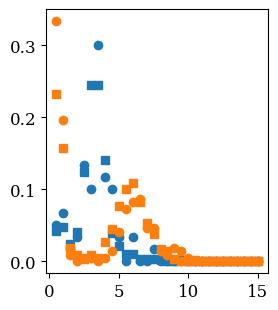

In [51]:

plt.rc('font', family='serif')
plt.rc('xtick', labelsize='large')
plt.rc('ytick', labelsize='large')
fig1 = plt.figure(figsize=(20,24))
k = 0
for i in range(0,15):
    plt.subplot(6,6,k+1)
    plt.plot(databins[1:len(databins)],E1_DRL_B_3hist[:,i], color = "tab:blue",  marker = "s", linestyle="None")
    plt.plot(databins[1:len(databins)],E1_DRL_PF_3hist[:,i], color = "tab:blue", marker = "o", linestyle="None")
    plt.plot(databins[1:len(databins)],E1_DRL_B_6hist[:,i], color = "tab:orange", marker = "s", linestyle="None")
    plt.plot(databins[1:len(databins)],E1_DRL_PF_6hist[:,i], color = "tab:orange", marker = "o", linestyle="None")
    plt.plot(fitbins[1:len(fitbins)], visDRL_B3[:,i], color = "tab:blue", linestyle="-")
    plt.plot(fitbins[1:len(fitbins)], visDRL_PF3[:,i], color = "tab:blue", linestyle=":")
    plt.plot(fitbins[1:len(fitbins)], visDRL_B6[:,i], color = "tab:orange", linestyle="-")
    plt.plot(fitbins[1:len(fitbins)], visDRL_PF6[:,i], color = "tab:orange", linestyle=":")
    plt.title(colwiseGA[i]+":DRL:Subject"+str(i+1))
    plt.subplot(6,6,k+2)
    plt.plot(databins[1:len(databins)],E1_FMI_B_3hist[:,i], color = "tab:blue", marker="s", linestyle="None")
    plt.plot(databins[1:len(databins)],E1_FMI_PF_3hist[:,i], color = "tab:blue", marker = "o", linestyle="None")
    plt.plot(databins[1:len(databins)],E1_FMI_B_6hist[:,i], color = "tab:orange",  marker="s", linestyle="None")
    plt.plot(databins[1:len(databins)],E1_FMI_PF_6hist[:,i], color = "tab:orange",marker = "o", linestyle="None")
    plt.plot(fitbins[1:len(fitbins)], visFMI_B3[:,i], color = "tab:blue", linestyle="-")
    plt.plot(fitbins[1:len(fitbins)], visFMI_PF3[:,i], color = "tab:blue", linestyle=":")
    plt.plot(fitbins[1:len(fitbins)], visFMI_B6[:,i], color = "tab:orange", linestyle="-")
    plt.plot(fitbins[1:len(fitbins)], visFMI_PF6[:,i], color = "tab:orange", linestyle=":")
    plt.title(colwiseGA[i]+":FMI:Subject"+str(i+1))
    k = k + 2

Now that we've calculated the predicted PDFs we can look at how well it describes the average PDF for each group under each condition.

In [52]:
#Sort data
LP_mean_DRL_PDFs = [np.nanmean(E1_DRL_B_3hist[:,LPindices],axis=1),np.nanmean(E1_DRL_PF_3hist[:,LPindices],axis=1),np.nanmean(E1_DRL_B_6hist[:,LPindices],axis=1),np.nanmean(E1_DRL_PF_6hist[:,LPindices_mod],axis=1)]
LP_mean_FMI_PDFs = [np.nanmean(E1_FMI_B_3hist[:,LPindices],axis=1),np.nanmean(E1_FMI_PF_3hist[:,LPindices],axis=1),np.nanmean(E1_FMI_B_6hist[:,LPindices],axis=1),np.nanmean(E1_FMI_PF_6hist[:,LPindices],axis=1)]
LP_mean_DRL_predPDFs = [np.nanmean(visDRL_B3[:,LPindices],axis=1),np.nanmean(visDRL_PF3[:,LPindices],axis=1),np.nanmean(visDRL_B6[:,LPindices],axis=1),np.nanmean(visDRL_PF6[:,LPindices_mod],axis=1)]
LP_mean_FMI_predPDFs = [np.nanmean(visFMI_B3[:,LPindices],axis=1),np.nanmean(visFMI_PF3[:,LPindices],axis=1),np.nanmean(visFMI_B6[:,LPindices],axis=1),np.nanmean(visFMI_PF6[:,LPindices],axis=1)]

NP_mean_DRL_PDFs = [np.nanmean(E1_DRL_B_3hist[:,NPindices],axis=1),np.nanmean(E1_DRL_PF_3hist[:,NPindices],axis=1),np.nanmean(E1_DRL_B_6hist[:,NPindices],axis=1),np.nanmean(E1_DRL_PF_6hist[:,NPindices],axis=1)]
NP_mean_FMI_PDFs = [np.nanmean(E1_FMI_B_3hist[:,NPindices],axis=1),np.nanmean(E1_FMI_PF_3hist[:,NPindices],axis=1),np.nanmean(E1_FMI_B_6hist[:,NPindices],axis=1),np.nanmean(E1_FMI_PF_6hist[:,NPindices],axis=1)]
NP_mean_DRL_predPDFs = [np.nanmean(visDRL_B3[:,NPindices],axis=1),np.nanmean(visDRL_PF3[:,NPindices],axis=1),np.nanmean(visDRL_B6[:,NPindices],axis=1),np.nanmean(visDRL_PF6[:,NPindices],axis=1)]
NP_mean_FMI_predPDFs = [np.nanmean(visFMI_B3[:,NPindices],axis=1),np.nanmean(visFMI_PF3[:,NPindices],axis=1),np.nanmean(visFMI_B6[:,NPindices],axis=1),np.nanmean(visFMI_PF6[:,NPindices],axis=1)]


#Plot data
plt.rc('font', family='serif')
plt.rc('xtick', labelsize='large')
plt.rc('ytick', labelsize='large')
fig2 = plt.figure(figsize=(16,12))
plt.subplot(2,2,1)
plt.plot(databins[1:len(databins)],LP_mean_DRL_PDFs[0], color = "tab:blue", linestyle="None", marker = "s",label = '3-s Baseline')
plt.plot(databins[1:len(databins)],LP_mean_DRL_PDFs[1], color = "tab:blue", linestyle="None", marker = "o",label = '3-s Pre-feeding',markerfacecolor="white",markeredgecolor='tab:blue', markeredgewidth=1)
plt.plot(databins[1:len(databins)],LP_mean_DRL_PDFs[2], color = "tab:orange", linestyle="None", marker = "s",label = '6-s Baseline')
plt.plot(databins[1:len(databins)],LP_mean_DRL_PDFs[3], color = "tab:orange", linestyle="None", marker = "o",label = '6-s Pre-feeding',markerfacecolor="white",markeredgecolor='tab:orange', markeredgewidth=1)
plt.plot(fitbins[1:len(fitbins)],LP_mean_DRL_predPDFs[0], color = "tab:blue", linestyle="-", linewidth=2,label = '3-s Baseline Fit')
plt.plot(fitbins[1:len(fitbins)],LP_mean_DRL_predPDFs[1], color = "tab:blue", linestyle=":", linewidth=2,label = '3-s Pre-feeding Fit')
plt.plot(fitbins[1:len(fitbins)],LP_mean_DRL_predPDFs[2], color = "tab:orange", linestyle="-", linewidth=2,label = '6-s Baseline Fit')
plt.plot(fitbins[1:len(fitbins)],LP_mean_DRL_predPDFs[3], color = "tab:orange", linestyle=":", linewidth=2,label = '6-s Pre-feeding Fit')
plt.title('LP DRL')
plt.legend()

plt.ylabel('P(Inter-Response Time = X)', fontsize = 14)
plt.subplot(2,2,3)
plt.plot(databins[1:len(databins)],LP_mean_FMI_PDFs[0], color = "tab:blue", linestyle="None", marker = "s")
plt.plot(databins[1:len(databins)],LP_mean_FMI_PDFs[1], color = "tab:blue", linestyle="None", marker = "o",markerfacecolor="white",markeredgecolor='tab:blue', markeredgewidth=1)
plt.plot(databins[1:len(databins)],LP_mean_FMI_PDFs[2], color = "tab:orange", linestyle="None", marker = "s")
plt.plot(databins[1:len(databins)],LP_mean_FMI_PDFs[3], color = "tab:orange", linestyle="None", marker = "o",markerfacecolor="white",markeredgecolor='tab:orange', markeredgewidth=1)
plt.plot(fitbins[1:len(fitbins)],LP_mean_FMI_predPDFs[0], color = "tab:blue", linestyle="-", linewidth=2)
plt.plot(fitbins[1:len(fitbins)],LP_mean_FMI_predPDFs[1], color = "tab:blue", linestyle=":", linewidth=2)
plt.plot(fitbins[1:len(fitbins)],LP_mean_FMI_predPDFs[2], color = "tab:orange", linestyle="-", linewidth=2)
plt.plot(fitbins[1:len(fitbins)],LP_mean_FMI_predPDFs[3], color = "tab:orange", linestyle=":", linewidth=2)
plt.title('LP FMI')


plt.subplot(2,2,2)
plt.plot(databins[1:len(databins)],NP_mean_DRL_PDFs[0], color = "tab:blue", linestyle="None", marker = "s")
plt.plot(databins[1:len(databins)],NP_mean_DRL_PDFs[1], color = "tab:blue", linestyle="None", marker = "o",markerfacecolor="white",markeredgecolor='tab:blue', markeredgewidth=1)
plt.plot(databins[1:len(databins)],NP_mean_DRL_PDFs[2], color = "tab:orange", linestyle="None", marker = "s")
plt.plot(databins[1:len(databins)],NP_mean_DRL_PDFs[3], color = "tab:orange", linestyle="None", marker = "o",markerfacecolor="white",markeredgecolor='tab:orange', markeredgewidth=1)
plt.plot(fitbins[1:len(fitbins)],NP_mean_DRL_predPDFs[0], color = "tab:blue", linestyle="-", linewidth=2)
plt.plot(fitbins[1:len(fitbins)],NP_mean_DRL_predPDFs[1], color = "tab:blue", linestyle=":", linewidth=2)
plt.plot(fitbins[1:len(fitbins)],NP_mean_DRL_predPDFs[2], color = "tab:orange", linestyle="-", linewidth=2)
plt.plot(fitbins[1:len(fitbins)],NP_mean_DRL_predPDFs[3], color = "tab:orange", linestyle=":", linewidth=2)
plt.ylabel('P(Inter-Response Time = X)', fontsize = 14)
plt.xlabel('Inter-Response Time (s)', fontsize = 14)
plt.title('NP DRL')


plt.subplot(2,2,4)
plt.plot(databins[1:len(databins)],NP_mean_FMI_PDFs[0], color = "tab:blue", linestyle="None", marker = "s")
plt.plot(databins[1:len(databins)],NP_mean_FMI_PDFs[1], color = "tab:blue", linestyle="None", marker = "o",markerfacecolor="white",markeredgecolor='tab:blue', markeredgewidth=1)
plt.plot(databins[1:len(databins)],NP_mean_FMI_PDFs[2], color = "tab:orange", linestyle="None", marker = "s")
plt.plot(databins[1:len(databins)],NP_mean_FMI_PDFs[3], color = "tab:orange", linestyle="None", marker = "o",markerfacecolor="white",markeredgecolor='tab:orange', markeredgewidth=1)
plt.plot(fitbins[1:len(fitbins)],NP_mean_FMI_predPDFs[0], color = "tab:blue", linestyle="-", linewidth=2)
plt.plot(fitbins[1:len(fitbins)],NP_mean_FMI_predPDFs[1], color = "tab:blue", linestyle=":", linewidth=2)
plt.plot(fitbins[1:len(fitbins)],NP_mean_FMI_predPDFs[2], color = "tab:orange", linestyle="-", linewidth=2)
plt.plot(fitbins[1:len(fitbins)],NP_mean_FMI_predPDFs[3], color = "tab:orange", linestyle=":", linewidth=2)
plt.xlabel('Inter-Response Time (s)', fontsize = 14)
plt.title('NP FMI')



NameError: name 'visDRL_B3' is not defined

Now that we've visualized the fit of our model let's analyze model parameters and derived statistics. 

First we will analyze derived statistics of the gamma distribution:
* mu = the mean timed response
* sd = variance of timed responses
* cv = sd/mu

Second we will analyze parameters common to all groups of mice in all conditions. 
* P = the probability of timing
* q (in TRe) and 1-P (in TR) = the probability of burst responding
* K_burst = the mean burst response time

Then we will analyze parameters common to only mice with the TRe model
* 1-q-P = the probability of lapsed responding
* K_lapse = the mean lapse response time


> **RESOLVED:** the cell below used to assign subject labels via `all_params.set_axis({...}, axis=1)` using a Python **set literal**, whose iteration order is randomized per process and could scramble which mouse was treated as LP or NP. Fixed by deriving the label list from `colwiseGA` (the positional, ordered list defined earlier in the notebook) instead:
> ```python
> subject_labels = [f"{grp}M{i+1}" for i, grp in enumerate(colwiseGA)]
> all_params = all_params.set_axis(subject_labels, axis=1)
> ```
> This produces the exact same 16 labels that were previously hand-typed into the set literal, but now in a guaranteed, reproducible order tied to the single source of truth (`colwiseGA`).

In [53]:
#parameters
all_params=pd.DataFrame(np.concatenate((DRL_B3_params,DRL_PF3_params,DRL_B6_params,DRL_PF6_params,FMI_B3_params,FMI_PF3_params,FMI_B6_params,FMI_PF6_params),axis=0))
subject_labels = [f"{grp}M{i+1}" for i, grp in enumerate(colwiseGA)]  # fixed: derived from colwiseGA (ordered), not a set literal
all_params=all_params.set_axis(subject_labels,axis=1)
all_params['Params'] = np.tile(['epsilon','c','P','Kburst','q','Klapse'],8)
all_params['Interval'] = np.repeat([3,3,6,6,3,3,6,6],6)
all_params['Motivation'] = np.repeat(['B','PF','B','PF','B','PF','B','PF'],6)
all_params['Schedule'] = np.repeat(['DRL','DRL','DRL','DRL','FMI','FMI','FMI','FMI'],6)
all_params = pd.melt(all_params,id_vars = ['Params','Interval','Motivation','Schedule'])
all_params['MouseID'] = 0
all_params['InitRsp'] = "NAN"
id_var, init_var = [],[]
for lbl in all_params.variable:
    id_var.append(int(re.findall(r'\d+',lbl)[0]))
    init_var.append(re.findall("[a-zA-Z]+",lbl)[0])
all_params['MouseID'] = id_var
all_params['InitRsp'] = init_var
all_params

NameError: name 'DRL_B3_params' is not defined

In [54]:
#derived statistics
all_derivedstats = pd.DataFrame()
all_derivedstats['mu'] = (all_params.value[all_params['Params']=='epsilon'].to_numpy()+1)*all_params.value[all_params['Params']=='c'].to_numpy()
all_derivedstats['sd'] = np.sqrt((all_params.value[all_params['Params']=='epsilon'].to_numpy()+1)*np.power(all_params.value[all_params['Params']=='c'].to_numpy(),2))
all_derivedstats['cv'] = all_derivedstats['sd'].to_numpy()/all_derivedstats['mu'].to_numpy()
all_derivedstats['Schedule'] = all_params.Schedule[all_params.Params=='epsilon'].tolist()
all_derivedstats['Motivation'] = all_params.Motivation[all_params.Params=='epsilon'].tolist()
all_derivedstats['Interval'] = all_params.Interval[all_params.Params=='epsilon'].tolist()
all_derivedstats['MouseID'] = all_params.MouseID[all_params.Params=='epsilon'].tolist()
all_derivedstats['InitRsp'] = all_params.InitRsp[all_params.Params=='epsilon'].tolist()
all_derivedstats = all_derivedstats.melt(id_vars=['Schedule','Motivation','Interval','MouseID','InitRsp'])
all_derivedstats = all_derivedstats[all_derivedstats['MouseID']<=15]
# M1's FMI TRe fit is degenerate (epsilon~48, q~0, Kburst==Klapse) -- exclude M1 from FMI only,
# it stays in for DRL where its fit is fine.
all_derivedstats = all_derivedstats[~((all_derivedstats['Schedule'] == 'FMI') & (all_derivedstats['MouseID'] == 1))]
all_derivedstats['lnValue'] = np.log(all_derivedstats.value)
all_derivedstats

NameError: name 'all_params' is not defined

KeyError: 'Schedule'

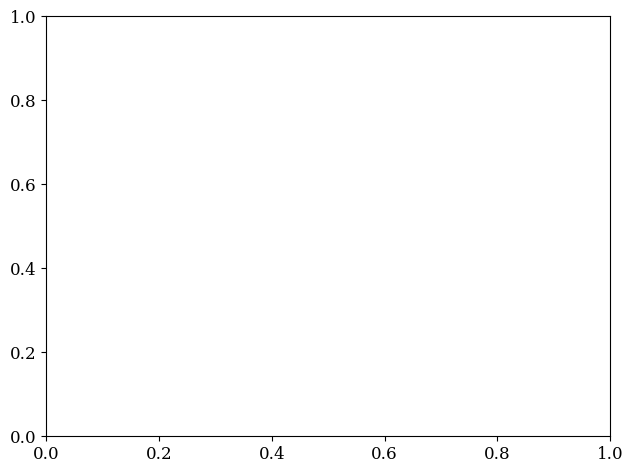

In [55]:
#Analysis of derived statistics; graphing then analysis
plt.rc('font', family='serif')
plt.rc('xtick', labelsize='large')
plt.rc('ytick', labelsize='large')
fig3 = plt.figure(figsize=(16,12))
plt.subplot(2,2,1)
sns.barplot(x="Interval",y="lnValue",hue="Motivation",ci=68,data=all_derivedstats[((all_derivedstats['Schedule']=="DRL") & (all_derivedstats['variable']=="mu") & (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('log(Gamma Mean (s))', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Nose Poke", fontsize=14)
plt.subplot(2,2,2)
sns.barplot(x="Interval",y="lnValue",hue="Motivation",ci=68,data=all_derivedstats[((all_derivedstats['Schedule']=="DRL") & (all_derivedstats['variable']=="mu")& (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('log(Gamma Mean (s))', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Lever Press", fontsize=14)
plt.subplot(2,2,3)
sns.barplot(x="Interval",y="lnValue",hue="Motivation",ci=68,data=all_derivedstats[((all_derivedstats['Schedule']=="FMI") & (all_derivedstats['variable']=="mu")& (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('log(Gamma Mean (s))', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("FMI: Nose Poke", fontsize=14)
plt.subplot(2,2,4)
sns.barplot(x="Interval",y="lnValue",hue="Motivation",ci=68,data=all_derivedstats[((all_derivedstats['Schedule']=="FMI") & (all_derivedstats['variable']=="mu")& (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('log(Gamma Mean (s))', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("FMI: Lever Press", fontsize=14)
plt.tight_layout()

KeyError: 'Schedule'

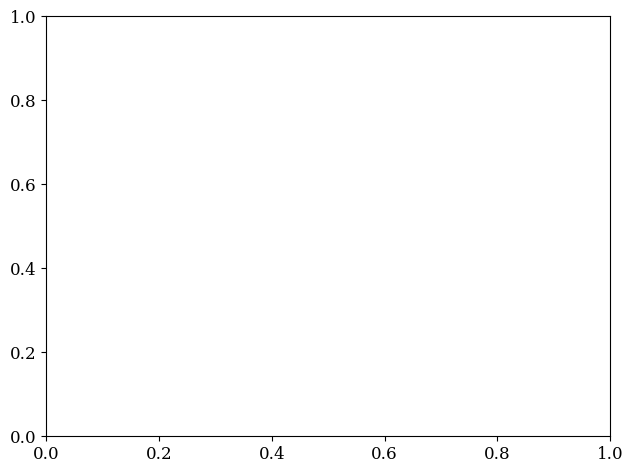

In [56]:
#Analysis of derived statistics; graphing then analysis
plt.rc('font', family='serif')
plt.rc('xtick', labelsize='large')
plt.rc('ytick', labelsize='large')
fig3 = plt.figure(figsize=(16,12))
plt.subplot(2,2,1)
sns.barplot(x="Interval",y="lnValue",hue="Motivation",ci=95,data=all_derivedstats[((all_derivedstats['Schedule']=="DRL") & (all_derivedstats['variable']=="sd") & (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('log(Gamma SD (s))', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Nose Poke", fontsize=14)
plt.subplot(2,2,2)
sns.barplot(x="Interval",y="lnValue",hue="Motivation",ci=95,data=all_derivedstats[((all_derivedstats['Schedule']=="DRL") & (all_derivedstats['variable']=="sd") & (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('log(Gamma SD (s))', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Lever Press", fontsize=14)
plt.subplot(2,2,3)
sns.barplot(x="Interval",y="lnValue",hue="Motivation",ci=95,data=all_derivedstats[((all_derivedstats['Schedule']=="FMI") & (all_derivedstats['variable']=="sd") & (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('log(Gamma SD (s))', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("FMI: Nose Poke", fontsize=14)
plt.subplot(2,2,4)
sns.barplot(x="Interval",y="lnValue",hue="Motivation",ci=95,data=all_derivedstats[((all_derivedstats['Schedule']=="FMI") & (all_derivedstats['variable']=="sd") & (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('log(Gamma SD (s))', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("FMI: Lever Press", fontsize=14)
plt.tight_layout()

KeyError: 'Schedule'

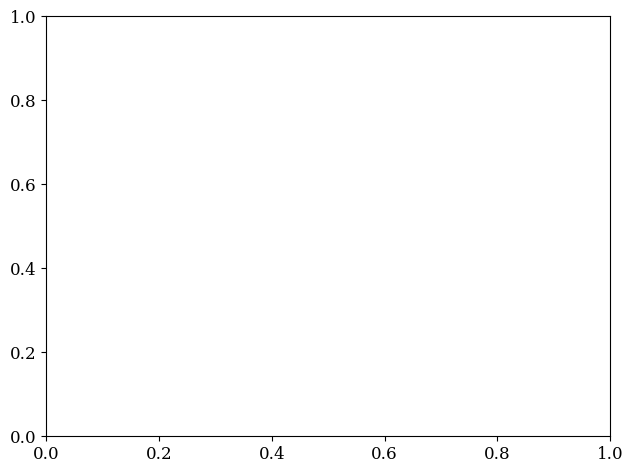

In [57]:
#Analysis of derived statistics; graphing then analysis
plt.rc('font', family='serif')
plt.rc('xtick', labelsize='large')
plt.rc('ytick', labelsize='large')
fig3 = plt.figure(figsize=(16,12))
plt.subplot(2,2,1)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_derivedstats[((all_derivedstats['Schedule']=="DRL") & (all_derivedstats['variable']=="cv") & (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('Gamma CV', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Nose Poke", fontsize=14)
plt.subplot(2,2,2)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_derivedstats[((all_derivedstats['Schedule']=="DRL") & (all_derivedstats['variable']=="cv") & (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('Gamma CV', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Lever Press", fontsize=14)
plt.subplot(2,2,3)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_derivedstats[((all_derivedstats['Schedule']=="FMI") & (all_derivedstats['variable']=="cv") & (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('Gamma CV', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("FMI: Nose Poke", fontsize=14)
plt.subplot(2,2,4)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_derivedstats[((all_derivedstats['Schedule']=="FMI") & (all_derivedstats['variable']=="cv") & (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('Gamma CV', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("FMI: Lever Press", fontsize=14)
plt.tight_layout()

To analyze the above graphs data will be analyzed in the following R file: see topography_gammaanalysis.Rmd


In [58]:
all_derivedstats.to_csv("topography_gamma.csv")


The output of the analysis conducted in R can be found as topograph_gamma.Rmd and .html in the Github repo. Here I summarize the main findings. Note that because mice were trained in sequence from DRL to FMI  

1. The mean of gamma distributed IRTs was sensitive to a main effect of interval and interaction of schedule and motivation (log-BF10 = 6.15). This indicates  that the mean of gamma distributed IRTs scaled with the waiting requirement (3-->6). Additionally, it indicates the mean of gamma distributed IRTs was sensitive differentially sensitive to motivation based on whether mice were performing in DRL or FMI. Probes of this interaction revealed that whereas pre-feeding increased the mean gamma distributed IRT in DRL (log-BF10 = 1.26), it had no effect in FMI (log-BF10 = -0.84). 
2. The sd of gamma distributed IRTs was only sensitive to the interval (log-BF10 = 5.18). This indicates that the sd of gamma distributed IRTs scaled with the waiting requirement. Taken together with the scaling of the mean of gamma distributed IRTs it suggests gamma distributed IRTs are scalar invariant. 
3. The CV of gamma distributed IRTs was not sensitive to manipulation, thus confirming the scalar property (largest log-BF10 = -0.51). 
4. Relative to the effects reported above and to the null model, there was no strong evidence for initiating response affecting gamma distributed IRTs (largest log-BF10 = -0.58). 


Taken together, these data suggest that the mean of gamma distributed IRTs is sensitive to flucutations in motivation when mice are trained in DRL but not FMI. We also replicated the typical finding that within a restricted range of intervals (seconds-minutes) timing performance is scalar invariant. Gamma distributed IRTs were not sensitive to initiating response. 

Next, we analyzed the remaining parameters of the mixture models. Note that whereas analyzing parameters of the gamma can help us map effects onto aspects of a pacemaker-accumulator model of interval timing (e.g., epsilon: threshold; c: clock-speed), the remaining parameters will help us characterize how frequently mice burst or lapse respond and the length of the IRTs generated under those modes. 

In [59]:
#add ln of values because not present 
all_params['lnValue']=1 #just establishing column because need to log-odds probabilities
all_params.lnValue[all_params['Params']=='epsilon']=np.log(all_params.value[all_params['Params']=="epsilon"])
all_params.lnValue[all_params['Params']=='c']=np.log(all_params.value[all_params['Params']=="c"])
all_params.lnValue[all_params['Params']=='Kburst']=np.log(all_params.value[all_params['Params']=="Kburst"])
all_params.lnValue[all_params['Params']=='Klapse']=np.log(all_params.value[all_params['Params']=="Klapse"])
all_params.lnValue[all_params['Params']=='P']=np.log((all_params.value[all_params['Params']=="P"]/(1-all_params.value[all_params['Params']=="P"])))
all_params.lnValue[all_params['Params']=='q']=np.log((all_params.value[all_params['Params']=="q"]/(1-all_params.value[all_params['Params']=="q"])))


NameError: name 'all_params' is not defined

In [60]:
display(all_params)

NameError: name 'all_params' is not defined

NameError: name 'all_params' is not defined

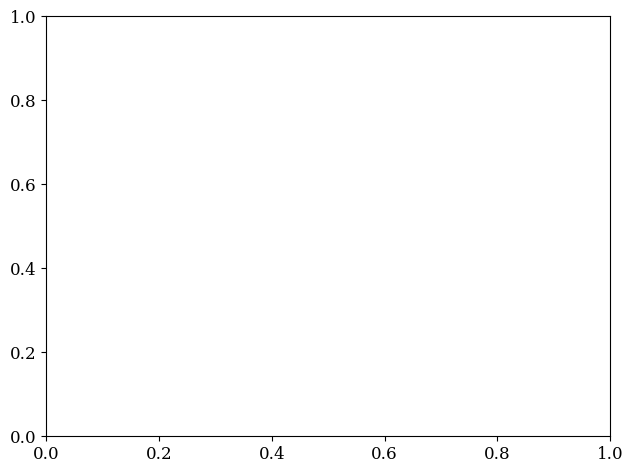

In [61]:
#Analysis of gamma parameters
plt.rc('font', family='serif')
plt.rc('xtick', labelsize='large')
plt.rc('ytick', labelsize='large')
fig3 = plt.figure(figsize=(16,12))
plt.subplot(2,2,1)
sns.barplot(x="Interval",y="lnValue",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="DRL") & (all_params['Params']=="epsilon")& (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('log(Epsilon)', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Nose Poke", fontsize=14)
plt.subplot(2,2,2)
sns.barplot(x="Interval",y="lnValue",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="DRL") & (all_params['Params']=="epsilon")& (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('log(Epsilon)', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Lever Press", fontsize=14)
plt.subplot(2,2,3)
sns.barplot(x="Interval",y="lnValue",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="FMI") & (all_params['Params']=="epsilon")& (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('log(Epsilon)', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("FMI: Nose Poke", fontsize=14)
plt.subplot(2,2,4)
sns.barplot(x="Interval",y="lnValue",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="FMI") & (all_params['Params']=="epsilon")& (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('log(Epsilon)', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("FMI: Lever Press", fontsize=14)
plt.tight_layout()

NameError: name 'all_params' is not defined

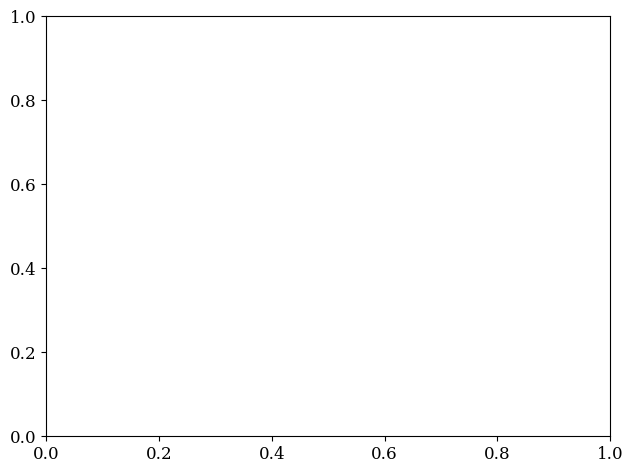

In [62]:
plt.rc('font', family='serif')
plt.rc('xtick', labelsize='large')
plt.rc('ytick', labelsize='large')
fig3 = plt.figure(figsize=(16,12))
plt.subplot(2,2,1)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="DRL") & (all_params['Params']=="c")& (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('c', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Nose Poke", fontsize=14)
plt.subplot(2,2,2)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="DRL") & (all_params['Params']=="c")& (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('c', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Lever Press", fontsize=14)
plt.subplot(2,2,3)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="FMI") & (all_params['Params']=="c")& (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('c', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("FMI: Nose Poke", fontsize=14)
plt.subplot(2,2,4)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="FMI") & (all_params['Params']=="c")& (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('c', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("FMI: Lever Press", fontsize=14)
plt.tight_layout()

NameError: name 'all_params' is not defined

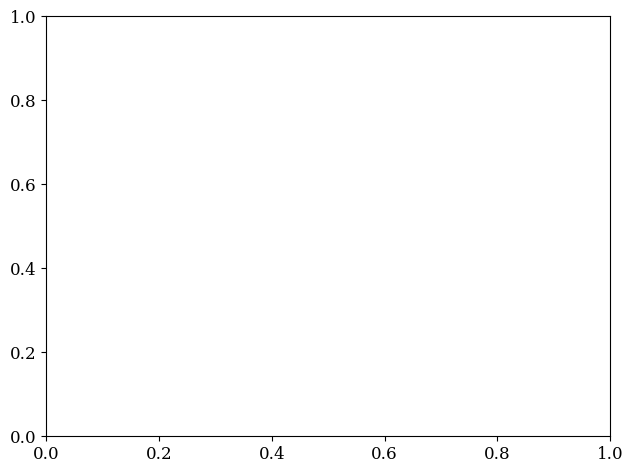

In [63]:
plt.rc('font', family='serif')
plt.rc('xtick', labelsize='large')
plt.rc('ytick', labelsize='large')
fig3 = plt.figure(figsize=(16,12))
plt.subplot(2,2,1)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="DRL") & (all_params['Params']=="P")& (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('P', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Nose Poke", fontsize=14)
plt.subplot(2,2,2)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="DRL") & (all_params['Params']=="P")& (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('P', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Lever Press", fontsize=14)
plt.subplot(2,2,3)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="FMI") & (all_params['Params']=="P")& (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('P', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("FMI: Nose Poke", fontsize=14)
plt.subplot(2,2,4)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="FMI") & (all_params['Params']=="P")& (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('P', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("FMI: Lever Press", fontsize=14)
plt.tight_layout()

NameError: name 'all_params' is not defined

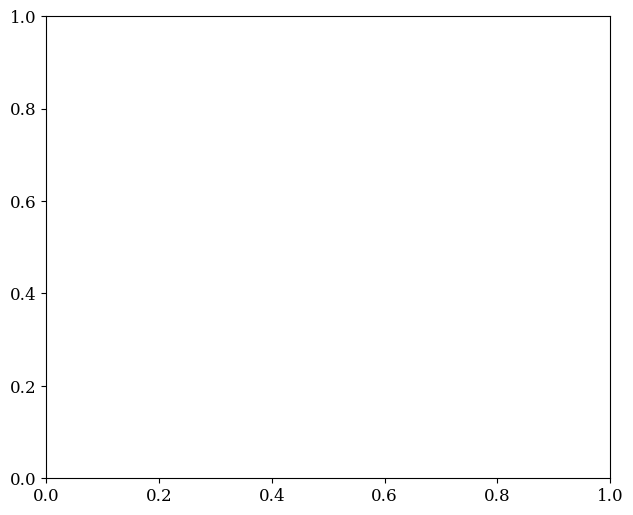

In [64]:
plt.rc('font', family='serif')
plt.rc('xtick', labelsize='large')
plt.rc('ytick', labelsize='large')
fig3 = plt.figure(figsize=(16,6))
plt.subplot(1,2,1)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="DRL") & (all_params['Params']=="q")& (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('q', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Nose Poke", fontsize=14)
plt.subplot(1,2,2)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="DRL") & (all_params['Params']=="q")& (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('q', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Lever Press", fontsize=14)
plt.tight_layout()

NameError: name 'all_params' is not defined

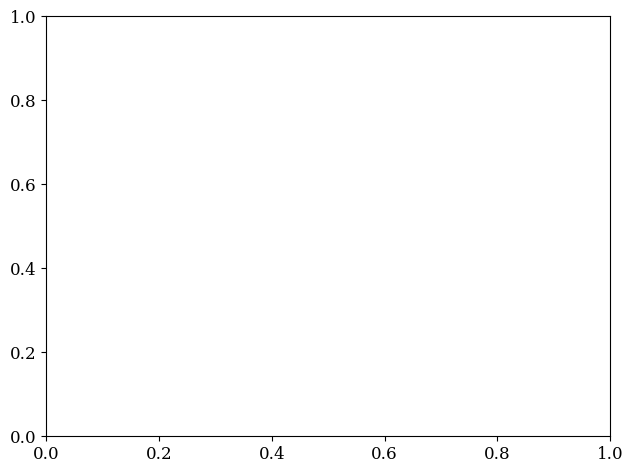

In [65]:
plt.rc('font', family='serif')
plt.rc('xtick', labelsize='large')
plt.rc('ytick', labelsize='large')
fig3 = plt.figure(figsize=(16,12))
plt.subplot(2,2,1)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="DRL") & (all_params['Params']=="Kburst")& (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('Kburst', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Nose Poke", fontsize=14)
plt.subplot(2,2,2)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="DRL") & (all_params['Params']=="Kburst")& (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('Kburst', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Lever Press", fontsize=14)
plt.subplot(2,2,3)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="FMI") & (all_params['Params']=="Kburst")& (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('Kburst', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("FMI: Nose Poke", fontsize=14)
plt.subplot(2,2,4)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="FMI") & (all_params['Params']=="Kburst")& (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('Kburst', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("FMI: Lever Press", fontsize=14)
plt.tight_layout()

NameError: name 'all_params' is not defined

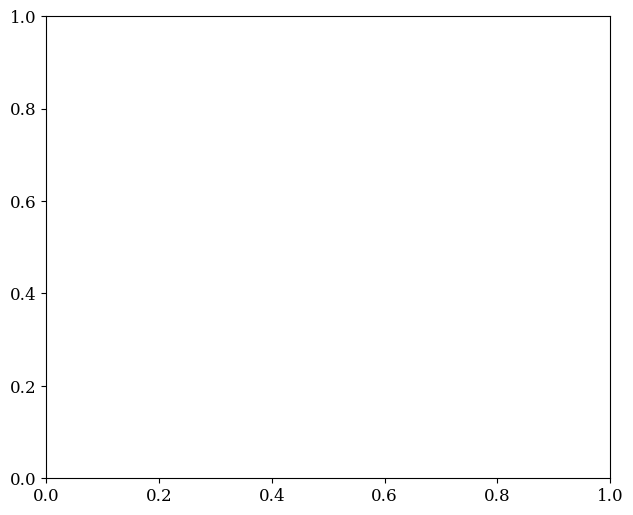

In [66]:
plt.rc('font', family='serif')
plt.rc('xtick', labelsize='large')
plt.rc('ytick', labelsize='large')
fig3 = plt.figure(figsize=(16,6))
plt.subplot(1,2,1)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="DRL") & (all_params['Params']=="Klapse")& (all_derivedstats['InitRsp']=="NPM"))],estimator=np.mean)
plt.ylabel('Klapse', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Nose Poke", fontsize=14)
plt.subplot(1,2,2)
sns.barplot(x="Interval",y="value",hue="Motivation",ci=68,data=all_params[((all_params['Schedule']=="DRL") & (all_params['Params']=="Klapse")& (all_derivedstats['InitRsp']=="LPM"))],estimator=np.mean)
plt.ylabel('Klapse', fontsize=14)
plt.xlabel('Interval (s)', fontsize=14)
plt.title("DRL: Lever Press", fontsize=14)
plt.tight_layout()

In [67]:
all_params.to_csv("topography_params.csv")


NameError: name 'all_params' is not defined

The output of the analysis conducted in R can be found as topography_params.Rmd and .html in the Github repo. Here I summarize the main findings. Note that because mice were trained in sequence from DRL to FMI  

1. No effects on Epsilon
2. c is sensitive to interval and initiating response
3. P is sensitive to motivation and schedule
4. K burst is sensitive to interval*Schedule, interval*init, schedule*init
5. DRL only: q is sensitive to interval*motivation*init
6. DRL only: K lapse is sensitive to interval (decreases with interval, schedule strain?) 

***REWRITE WITH NARRATIVE and log-BF10***

## Median IRT summary: DRL vs FMI (Experiment 1, raw empirical IRTs)

Two summary graphs, one per schedule (DRL, FMI). For each schedule, the median IRT is computed per mouse (across that mouse's trials), separately for each wait requirement (3 s, 6 s) and feeding condition (baseline, pre-feeding). The bar height is the median across the 15 mice; individual mouse medians are overlaid as points.

Subject 16 died before completing the FMI schedule, so it is excluded from both schedules to keep the same 15 mice throughout.

### Shared plotting style

One style module for every Median IRT figure — current and future. Centralizes fonts, the wait-requirement color mapping, and a `save_figure` helper that writes both a PDF and a PNG for each figure, so new graphs stay visually consistent with these without re-deriving the style.

In [68]:
# --- Shared plotting style: fonts, colors, and figure export ---
from pathlib import Path
import matplotlib.patheffects as pe

# Fonts (matches the serif style used elsewhere in this notebook)
plt.rc("font", family="serif")
plt.rc("axes", titlesize=13, labelsize=11)
plt.rc("xtick", labelsize=10)
plt.rc("ytick", labelsize=10)
plt.rc("legend", fontsize=10)

# Colors
COLOR_WAIT = {3: "red", 6: "blue"}   # wait requirement -> hue
CONDITION_COLOR = {"Baseline": "red", "Pre-feeding": "blue"}   # feeding condition -> hue (distribution figures)
OBSERVED_LINEWIDTH = 3.5   # dotted "observed" lines (bigger dots = thicker dotted line)
FIT_LINEWIDTH = 2   # solid "model fit" lines
LEGEND_STROKE_WIDTH = 0.4   # legend label text: thin text-stroke for a weight between normal and bold
BASELINE_ALPHA = 0.9
PREFEED_ALPHA = 0.45
POINT_COLOR = "black"
POINT_ALPHA = 0.6
POINT_SIZE = 30
BOX_LINEWIDTH = 1.8   # box edges, whiskers, caps
MEDIAN_LINEWIDTH = 2.0

# Where saved figures go (created on first use)
FIGURE_DIR = Path("figures")


def style_axes(ax):
    """Strip the top/right spines so every figure shares the same frame."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    return ax


def save_figure(fig, name, directory=FIGURE_DIR):
    """Save `fig` as both PDF and PNG under `directory/name.{pdf,png}`."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    fig.savefig(directory / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(directory / f"{name}.png", bbox_inches="tight", dpi=300)

In [69]:
# --- Median IRT summary: setup ---
import numpy as np
import matplotlib.pyplot as plt

MAT_PATH = "/Users/annikanallaballi/Data-Extraction-Method-for-CAB_LAB/mouse-topographic-withholding/IRTs_TRmodel1.mat"
if 'matlab_database' not in dir():
    import scipy.io as spio
    matlab_database = spio.loadmat(MAT_PATH, squeeze_me=True)


def median_irt_by_condition(baseline_var, prefeed_var, subject_indices):
    """Per-mouse median IRT, split by feeding condition and wait requirement, for one topography group."""
    out = {}
    for label, var in [("Baseline", baseline_var), ("Pre-feeding", prefeed_var)]:
        arr = matlab_database[var]
        medians = {}
        for wait in (3, 6):
            block = arr[arr[:, -1] == wait, 2:-1][:, subject_indices]
            medians[wait] = np.nanmedian(block, axis=0)  # one value per mouse
        out[label] = medians
    return out


# LPindices/NPindices come from colwiseGA (cell 7); NPindices already excludes M16 (no FMI data).
drl_data_lp = median_irt_by_condition("DRL_exp1", "DRL_exp1_PF", LPindices)
drl_data_np = median_irt_by_condition("DRL_exp1", "DRL_exp1_PF", NPindices)
fmi_data_lp = median_irt_by_condition("FMI_exp1", "FMI_exp1_PF", LPindices)
fmi_data_np = median_irt_by_condition("FMI_exp1", "FMI_exp1_PF", NPindices)

### Median IRT box plots: Baseline vs. Pre-feeding, split by schedule and wait requirement

Four graphs: DRL-3s, DRL-6s, FMI-3s, FMI-6s. Each graph has 4 box plots grouped in two pairs — Baseline (LP, NP) and Pre-feeding (LP, NP) — built from that group's per-mouse median IRTs (n=8 LP mice, n=7 NP mice). Color marks the wait requirement (red = 3 s, blue = 6 s); a hatched/lighter fill marks Pre-feeding vs. a solid fill for Baseline. Each box is labeled LP or NP on the x-axis; the Baseline/Pre-feeding grouping is labeled below that. Y-axis ticks step by a fixed interval across all four graphs so they're visually comparable, even though each graph keeps its own data range. Individual mouse medians are overlaid as jittered points.

In [70]:
# --- Shared box-plot builder (used by Median IRT and CQV figures) ---
from matplotlib.ticker import MultipleLocator

BOX_POSITIONS = [1, 2, 3.5, 4.5]   # Baseline-LP, Baseline-NP | Pre-feeding-LP, Pre-feeding-NP
BOX_GROUP_LABELS = ["LP", "NP", "LP", "NP"]
BOX_CONDITIONS = ["Baseline", "Baseline", "Pre-feeding", "Pre-feeding"]


def plot_stat_box(drl_lp_data, drl_np_data, fmi_lp_data, fmi_np_data, wait, schedule_name,
                   ylabel="Median IRT (s)", tick_interval=1.0):
    if schedule_name == "DRL":
        lp_data, np_data = drl_lp_data, drl_np_data
    else:
        lp_data, np_data = fmi_lp_data, fmi_np_data

    data = [lp_data["Baseline"][wait], np_data["Baseline"][wait],
            lp_data["Pre-feeding"][wait], np_data["Pre-feeding"][wait]]
    color = COLOR_WAIT[wait]

    # Shared y-axis scale across DRL and FMI for this wait requirement (pooled from both schedules)
    all_vals = np.concatenate([
        drl_lp_data["Baseline"][wait], drl_np_data["Baseline"][wait],
        drl_lp_data["Pre-feeding"][wait], drl_np_data["Pre-feeding"][wait],
        fmi_lp_data["Baseline"][wait], fmi_np_data["Baseline"][wait],
        fmi_lp_data["Pre-feeding"][wait], fmi_np_data["Pre-feeding"][wait],
    ])
    y_pad = (all_vals.max() - all_vals.min()) * 0.08
    ylim = (all_vals.min() - y_pad, all_vals.max() + y_pad)

    fig, ax = plt.subplots(figsize=(5.5, 5))
    bp = ax.boxplot(data, positions=BOX_POSITIONS, patch_artist=True, widths=0.5, showfliers=False,
                     medianprops=dict(color="black", linewidth=MEDIAN_LINEWIDTH),
                     whiskerprops=dict(color="black", linewidth=BOX_LINEWIDTH),
                     capprops=dict(color="black", linewidth=BOX_LINEWIDTH))

    for patch, cond in zip(bp["boxes"], BOX_CONDITIONS):
        patch.set_facecolor(color)
        patch.set_edgecolor("black")
        patch.set_linewidth(BOX_LINEWIDTH)
        if cond == "Pre-feeding":
            patch.set_alpha(PREFEED_ALPHA)
            patch.set_hatch("//")
        else:
            patch.set_alpha(BASELINE_ALPHA)

    rng = np.random.default_rng(0)
    for pos, values in zip(BOX_POSITIONS, data):
        jitter = rng.uniform(-0.08, 0.08, size=len(values))
        ax.scatter(np.full_like(values, pos) + jitter, values, s=POINT_SIZE, color=POINT_COLOR,
                   alpha=POINT_ALPHA, zorder=3, linewidths=0)

    ax.set_xticks(BOX_POSITIONS)
    ax.set_xticklabels(BOX_GROUP_LABELS)
    ax.text((BOX_POSITIONS[0] + BOX_POSITIONS[1]) / 2, -0.12, "Baseline",
            transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=10)
    ax.text((BOX_POSITIONS[2] + BOX_POSITIONS[3]) / 2, -0.12, "Pre-feeding",
            transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=10)

    ax.set_ylabel(ylabel)
    ax.set_title(f"{schedule_name}: {wait} s schedule (n=8 LP, n=7 NP)")
    ax.set_ylim(ylim)
    ax.yaxis.set_major_locator(MultipleLocator(tick_interval))
    style_axes(ax)
    fig.tight_layout()
    return fig, ax

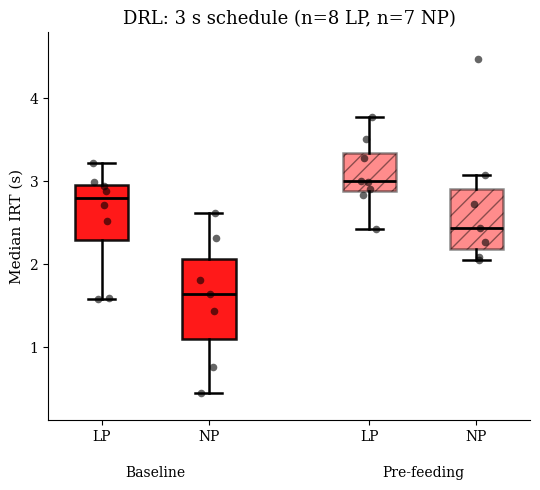

In [71]:
fig, ax = plot_stat_box(drl_data_lp, drl_data_np, fmi_data_lp, fmi_data_np, 3, "DRL",
                        ylabel="Median IRT (s)", tick_interval=1.0)
save_figure(fig, "DRL_3s_median_IRT")
plt.show()

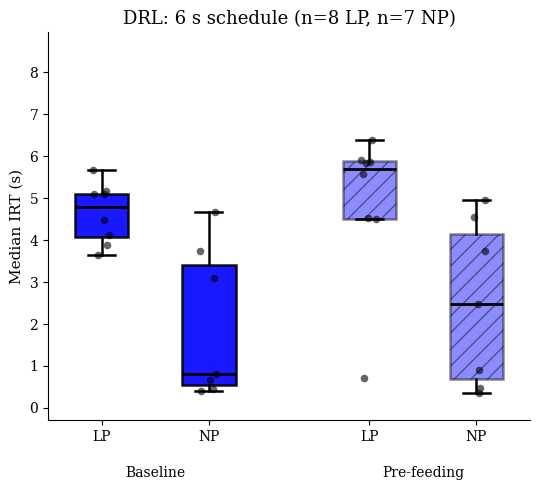

In [72]:
fig, ax = plot_stat_box(drl_data_lp, drl_data_np, fmi_data_lp, fmi_data_np, 6, "DRL",
                        ylabel="Median IRT (s)", tick_interval=1.0)
save_figure(fig, "DRL_6s_median_IRT")
plt.show()

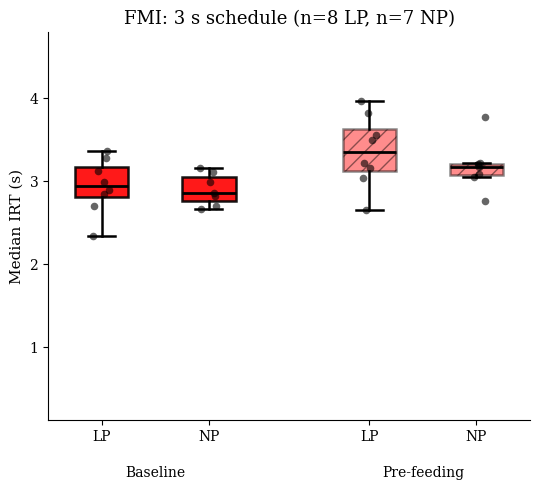

In [73]:
fig, ax = plot_stat_box(drl_data_lp, drl_data_np, fmi_data_lp, fmi_data_np, 3, "FMI",
                        ylabel="Median IRT (s)", tick_interval=1.0)
save_figure(fig, "FMI_3s_median_IRT")
plt.show()

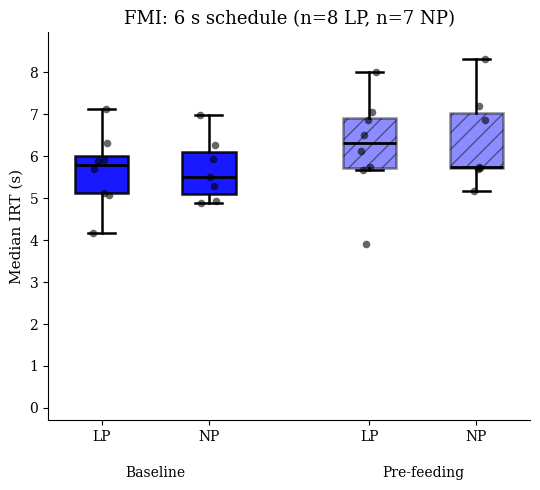

In [74]:
fig, ax = plot_stat_box(drl_data_lp, drl_data_np, fmi_data_lp, fmi_data_np, 6, "FMI",
                        ylabel="Median IRT (s)", tick_interval=1.0)
save_figure(fig, "FMI_6s_median_IRT")
plt.show()

### CQV box plots: Baseline vs. Pre-feeding, split by schedule and wait requirement

Same layout as the Median IRT box plots above (4 graphs, 4 boxes each: Baseline-LP, Baseline-NP, Pre-feeding-LP, Pre-feeding-NP), plotting the coefficient of quartile variation instead: CQV = (Q3 − Q1) / (Q3 + Q1), computed per mouse from that mouse's IRTs (same trial data, same LP/NP split: n=8 LP, n=7 NP). Y-axis ticks step by a fixed interval across all four graphs. CQV is a robust, quartile-based measure of spread — the empirical counterpart to the model-based CV shown in the gamma statistic charts further down.

In [75]:
# --- CQV summary: setup ---
def cqv_by_condition(baseline_var, prefeed_var, subject_indices):
    """Per-mouse CQV = (Q3-Q1)/(Q3+Q1) of IRTs, split by feeding condition and wait requirement, for one topography group."""
    out = {}
    for label, var in [("Baseline", baseline_var), ("Pre-feeding", prefeed_var)]:
        arr = matlab_database[var]
        cqvs = {}
        for wait in (3, 6):
            block = arr[arr[:, -1] == wait, 2:-1][:, subject_indices]
            q1 = np.nanpercentile(block, 25, axis=0)
            q3 = np.nanpercentile(block, 75, axis=0)
            cqvs[wait] = (q3 - q1) / (q3 + q1)  # one value per mouse
        out[label] = cqvs
    return out


drl_cqv_data_lp = cqv_by_condition("DRL_exp1", "DRL_exp1_PF", LPindices)
drl_cqv_data_np = cqv_by_condition("DRL_exp1", "DRL_exp1_PF", NPindices)
fmi_cqv_data_lp = cqv_by_condition("FMI_exp1", "FMI_exp1_PF", LPindices)
fmi_cqv_data_np = cqv_by_condition("FMI_exp1", "FMI_exp1_PF", NPindices)

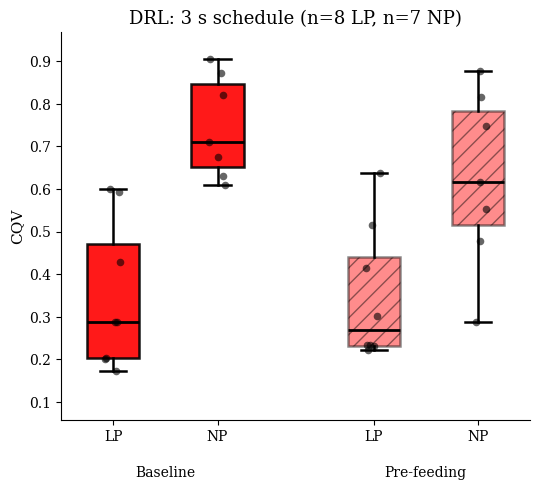

In [76]:
fig, ax = plot_stat_box(drl_cqv_data_lp, drl_cqv_data_np, fmi_cqv_data_lp, fmi_cqv_data_np, 3, "DRL",
                        ylabel="CQV", tick_interval=0.1)
save_figure(fig, "DRL_3s_CQV")
plt.show()

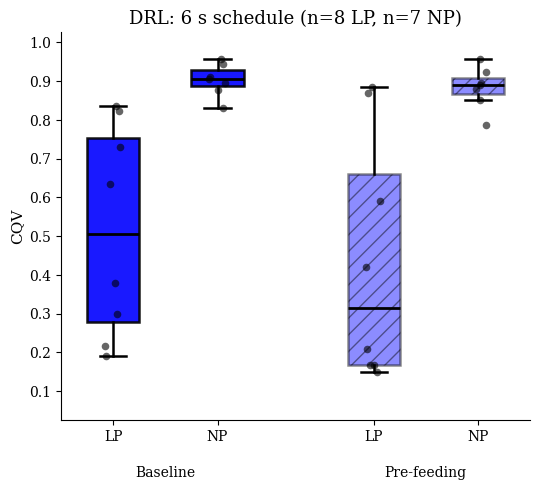

In [77]:
fig, ax = plot_stat_box(drl_cqv_data_lp, drl_cqv_data_np, fmi_cqv_data_lp, fmi_cqv_data_np, 6, "DRL",
                        ylabel="CQV", tick_interval=0.1)
save_figure(fig, "DRL_6s_CQV")
plt.show()

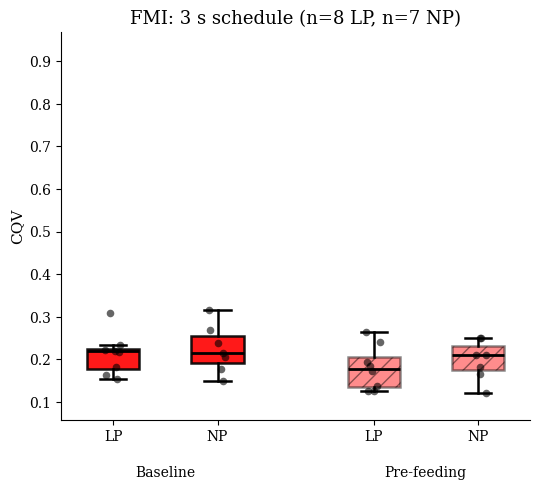

In [78]:
fig, ax = plot_stat_box(drl_cqv_data_lp, drl_cqv_data_np, fmi_cqv_data_lp, fmi_cqv_data_np, 3, "FMI",
                        ylabel="CQV", tick_interval=0.1)
save_figure(fig, "FMI_3s_CQV")
plt.show()

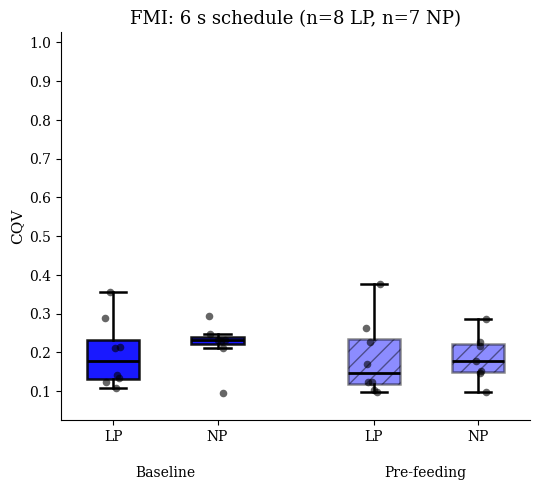

In [79]:
fig, ax = plot_stat_box(drl_cqv_data_lp, drl_cqv_data_np, fmi_cqv_data_lp, fmi_cqv_data_np, 6, "FMI",
                        ylabel="CQV", tick_interval=0.1)
save_figure(fig, "FMI_6s_CQV")
plt.show()

## Group-average distribution figures & gamma statistics (LP vs. NP, DRL vs. FMI)

Builds on the data already computed above (empirical PDFs, TRe/TR model fits from cell 17; `all_derivedstats` from cell 21 — now using the corrected LP/NP labels). Uses the shared style module defined earlier (`style_axes`, `save_figure`, `COLOR_WAIT`).

### Group-average distribution figures

One figure per Schedule × LP/NP × wait requirement (8 figures total: DRL-NP-3s, DRL-NP-6s, DRL-LP-3s, DRL-LP-6s, FMI-NP-3s, FMI-NP-6s, FMI-LP-3s, FMI-LP-6s). Each figure shows Baseline and Pre-feeding together — observed (empirical) data as dotted lines, TRe/TR model fit as solid lines. Color marks the feeding condition (red = Baseline, blue = Pre-feeding), consistent across both wait requirements.

In [80]:
# --- Group-average distribution figures ---
# LP_mean_*_PDFs / *_predPDFs are ordered [3-s Baseline, 3-s Pre-feeding, 6-s Baseline, 6-s Pre-feeding]
DIST_WAIT_SLICE = {3: (0, 1), 6: (2, 3)}


def plot_group_distribution_by_wait(emp_pdfs, fit_pdfs, wait, schedule_name, group_name):
    b_idx, pf_idx = DIST_WAIT_SLICE[wait]

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(databins[1:len(databins)], emp_pdfs[b_idx], color=CONDITION_COLOR["Baseline"],
            linestyle=":", linewidth=OBSERVED_LINEWIDTH, label="Baseline (observed)")
    ax.plot(fitbins[1:len(fitbins)], fit_pdfs[b_idx], color=CONDITION_COLOR["Baseline"],
            linestyle="-", linewidth=FIT_LINEWIDTH, label="Baseline (model fit)")
    ax.plot(databins[1:len(databins)], emp_pdfs[pf_idx], color=CONDITION_COLOR["Pre-feeding"],
            linestyle=":", linewidth=OBSERVED_LINEWIDTH, label="Pre-feeding (observed)")
    ax.plot(fitbins[1:len(fitbins)], fit_pdfs[pf_idx], color=CONDITION_COLOR["Pre-feeding"],
            linestyle="-", linewidth=FIT_LINEWIDTH, label="Pre-feeding (model fit)")

    ax.set_xlabel("Inter-Response Time (s)")
    ax.set_ylabel("P(Inter-Response Time = X)")
    ax.set_title(f"{group_name}: {schedule_name}, {wait} s schedule")
    style_axes(ax)
    leg = ax.legend(frameon=False, fontsize=8)
    for text in leg.get_texts():
        text.set_path_effects([pe.withStroke(linewidth=LEGEND_STROKE_WIDTH, foreground="black")])
    fig.tight_layout()
    return fig, ax

In [81]:
DIST_GROUPS = [
    ("DRL", "NP", NP_mean_DRL_PDFs, NP_mean_DRL_predPDFs),
    ("DRL", "LP", LP_mean_DRL_PDFs, LP_mean_DRL_predPDFs),
    ("FMI", "NP", NP_mean_FMI_PDFs, NP_mean_FMI_predPDFs),
    ("FMI", "LP", LP_mean_FMI_PDFs, LP_mean_FMI_predPDFs),
]

for schedule_name, group_name, emp, fit in DIST_GROUPS:
    for wait in (3, 6):
        fig, ax = plot_group_distribution_by_wait(emp, fit, wait, schedule_name, group_name)
        save_figure(fig, f"{schedule_name}_{group_name}_{wait}s_distribution")
        plt.show()

NameError: name 'NP_mean_DRL_PDFs' is not defined

### Gamma statistic bar charts (mean, SD, CV)

One bar chart per statistic (mean, SD, CV) × group (DRL/FMI × Nose Poke/Lever Press) — 12 figures total. Matches the original chart type and error-bar convention exactly (grouped bar, x = Interval, hue = Motivation, 68% CI for mean/CV, 95% CI for SD), split into individually saved figures instead of one combined 2×2 grid.

In [82]:
# --- Gamma statistic box plots (mean, SD, CV) ---
from matplotlib.patches import Patch

GAMMA_STATS = {
    "mu": ("lnValue", "log(Gamma Mean (s))"),
    "sd": ("lnValue", "log(Gamma SD (s))"),
    "cv": ("value", "Gamma CV"),
}
GAMMA_GROUPS = [
    ("DRL", "NPM", "Nose Poke"),
    ("DRL", "LPM", "Lever Press"),
    ("FMI", "NPM", "Nose Poke"),
    ("FMI", "LPM", "Lever Press"),
]
GAMMA_MOTIVATION_COLOR = {"B": CONDITION_COLOR["Baseline"], "PF": CONDITION_COLOR["Pre-feeding"]}
GAMMA_MOTIVATION_LABEL = {"B": "Baseline", "PF": "Pre-feeding"}
GAMMA_BOX_POSITIONS = [1, 2, 3.5, 4.5]   # 3s-Baseline, 3s-Pre-feeding | 6s-Baseline, 6s-Pre-feeding
GAMMA_BOX_INTERVALS = [3, 3, 6, 6]
GAMMA_BOX_CONDITIONS = ["B", "PF", "B", "PF"]
# A little thicker than the shared box-plot defaults, kept local to this section only.
GAMMA_BOX_LINEWIDTH = BOX_LINEWIDTH + 0.6
GAMMA_MEDIAN_LINEWIDTH = MEDIAN_LINEWIDTH + 0.6


def plot_gamma_stat(stat, schedule, init_rsp, group_label):
    y_col, ylabel = GAMMA_STATS[stat]
    subset = all_derivedstats[(all_derivedstats["Schedule"] == schedule) &
                               (all_derivedstats["variable"] == stat) &
                               (all_derivedstats["InitRsp"] == init_rsp)]

    data = [subset[(subset["Interval"] == interval) & (subset["Motivation"] == motivation)][y_col].to_numpy()
            for interval, motivation in zip(GAMMA_BOX_INTERVALS, GAMMA_BOX_CONDITIONS)]

    fig, ax = plt.subplots(figsize=(4.5, 5))
    # Same box style as the Median IRT/CQV panels: notched off, white fill, colored outline,
    # dashed black whiskers, black median. Color here still marks feeding condition (red=Baseline,
    # blue=Pre-feeding), matching the original bar chart's color scheme.
    bp = ax.boxplot(data, positions=GAMMA_BOX_POSITIONS, patch_artist=True, widths=0.5, showfliers=False,
                     notch=False,
                     medianprops=dict(color="black", linewidth=GAMMA_MEDIAN_LINEWIDTH),
                     whiskerprops=dict(color="black", linewidth=GAMMA_BOX_LINEWIDTH, linestyle="--"),
                     capprops=dict(color="black", linewidth=GAMMA_BOX_LINEWIDTH))

    for patch, motivation in zip(bp["boxes"], GAMMA_BOX_CONDITIONS):
        patch.set_facecolor("white")
        patch.set_edgecolor(GAMMA_MOTIVATION_COLOR[motivation])
        patch.set_linewidth(GAMMA_BOX_LINEWIDTH)

    rng = np.random.default_rng(0)
    for pos, values in zip(GAMMA_BOX_POSITIONS, data):
        jitter = rng.uniform(-0.08, 0.08, size=len(values))
        ax.scatter(np.full_like(values, pos) + jitter, values, s=POINT_SIZE, color=POINT_COLOR,
                   alpha=POINT_ALPHA, zorder=3, linewidths=0)

    ax.set_xticks([1.5, 4.0])
    ax.set_xticklabels(["3", "6"])
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Interval (s)")
    ax.set_title(f"{schedule}: {group_label}")
    style_axes(ax)

    legend_handles = [
        Patch(facecolor="white", edgecolor=GAMMA_MOTIVATION_COLOR["B"], linewidth=GAMMA_BOX_LINEWIDTH,
              label="Baseline"),
        Patch(facecolor="white", edgecolor=GAMMA_MOTIVATION_COLOR["PF"], linewidth=GAMMA_BOX_LINEWIDTH,
              label="Pre-feeding"),
    ]
    ax.legend(handles=legend_handles, frameon=False)

    fig.tight_layout()
    return fig, ax

In [83]:
for stat in GAMMA_STATS:
    for schedule, init_rsp, group_label in GAMMA_GROUPS:
        fig, ax = plot_gamma_stat(stat, schedule, init_rsp, group_label)
        save_figure(fig, f"{schedule}_{init_rsp}_{stat}")
        plt.show()

KeyError: 'Schedule'

### Median IRT box plots, arranged by condition: DRL vs. FMI, NP vs. LP

A second view of the same Median IRT data, arranged differently: Baseline and Pre-feeding are now on separate graphs (4 total: Baseline-3s, Baseline-6s, Pre-feeding-3s, Pre-feeding-6s). Each graph has 4 box plots grouped in two pairs — DRL (NP, LP) and FMI (NP, LP) — using the same per-mouse median IRTs computed earlier (n=8 LP, n=7 NP). Color still marks the wait requirement (red = 3 s, blue = 6 s); solid fill = DRL, hatched fill = FMI. Each box is labeled NP or LP on the x-axis, with a DRL/FMI group label below. Same fixed y-axis tick interval (1 unit) as the other Median IRT graphs.

In [84]:
# --- Median IRT box plots, arranged by condition (DRL vs FMI, NP vs LP) ---
COMBINED_POSITIONS = [1, 2, 3.5, 4.5]   # DRL-NP, DRL-LP | FMI-NP, FMI-LP
COMBINED_GROUP_LABELS = ["NP", "LP", "NP", "LP"]
COMBINED_SCHEDULES = ["DRL", "DRL", "FMI", "FMI"]


def plot_stat_by_schedule(drl_lp_data, drl_np_data, fmi_lp_data, fmi_np_data, condition, wait,
                           ylabel="Median IRT (s)", tick_interval=1.0):
    data = [drl_np_data[condition][wait], drl_lp_data[condition][wait],
            fmi_np_data[condition][wait], fmi_lp_data[condition][wait]]
    color = COLOR_WAIT[wait]

    # Shared y-axis scale across Baseline and Pre-feeding for this wait requirement, so the two
    # condition graphs at the same wait are directly comparable (pooled from both conditions).
    all_vals = np.concatenate([
        drl_lp_data["Baseline"][wait], drl_np_data["Baseline"][wait],
        fmi_lp_data["Baseline"][wait], fmi_np_data["Baseline"][wait],
        drl_lp_data["Pre-feeding"][wait], drl_np_data["Pre-feeding"][wait],
        fmi_lp_data["Pre-feeding"][wait], fmi_np_data["Pre-feeding"][wait],
    ])
    y_pad = (all_vals.max() - all_vals.min()) * 0.08
    ylim = (all_vals.min() - y_pad, all_vals.max() + y_pad)

    fig, ax = plt.subplots(figsize=(5.5, 5))
    bp = ax.boxplot(data, positions=COMBINED_POSITIONS, patch_artist=True, widths=0.5, showfliers=False,
                     medianprops=dict(color="black", linewidth=MEDIAN_LINEWIDTH),
                     whiskerprops=dict(color="black", linewidth=BOX_LINEWIDTH),
                     capprops=dict(color="black", linewidth=BOX_LINEWIDTH))

    for patch, schedule in zip(bp["boxes"], COMBINED_SCHEDULES):
        patch.set_facecolor(color)
        patch.set_edgecolor("black")
        patch.set_linewidth(BOX_LINEWIDTH)
        if schedule == "FMI":
            patch.set_alpha(PREFEED_ALPHA)
            patch.set_hatch("//")
        else:
            patch.set_alpha(BASELINE_ALPHA)

    rng = np.random.default_rng(0)
    for pos, values in zip(COMBINED_POSITIONS, data):
        jitter = rng.uniform(-0.08, 0.08, size=len(values))
        ax.scatter(np.full_like(values, pos) + jitter, values, s=POINT_SIZE, color=POINT_COLOR,
                   alpha=POINT_ALPHA, zorder=3, linewidths=0)

    ax.set_xticks(COMBINED_POSITIONS)
    ax.set_xticklabels(COMBINED_GROUP_LABELS)
    ax.text((COMBINED_POSITIONS[0] + COMBINED_POSITIONS[1]) / 2, -0.12, "DRL",
            transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=10)
    ax.text((COMBINED_POSITIONS[2] + COMBINED_POSITIONS[3]) / 2, -0.12, "FMI",
            transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=10)

    ax.set_ylabel(ylabel)
    ax.set_title(f"{condition}: {wait} s schedule (n=8 LP, n=7 NP)")
    ax.set_ylim(ylim)
    ax.yaxis.set_major_locator(MultipleLocator(tick_interval))
    style_axes(ax)
    fig.tight_layout()
    return fig, ax

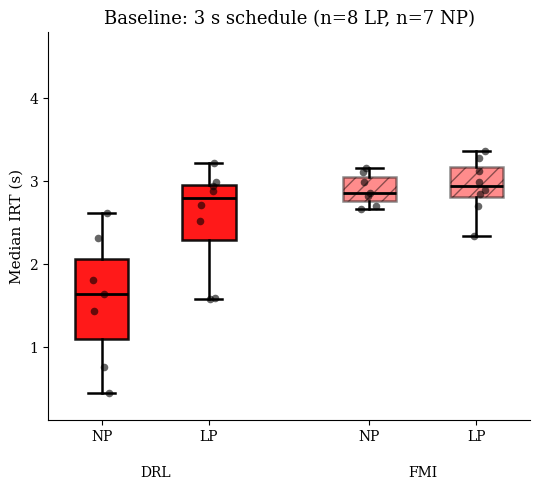

In [85]:
fig, ax = plot_stat_by_schedule(drl_data_lp, drl_data_np, fmi_data_lp, fmi_data_np,
                                 "Baseline", 3, ylabel="Median IRT (s)", tick_interval=1.0)
save_figure(fig, "Baseline_3s_median_IRT_by_schedule")
plt.show()

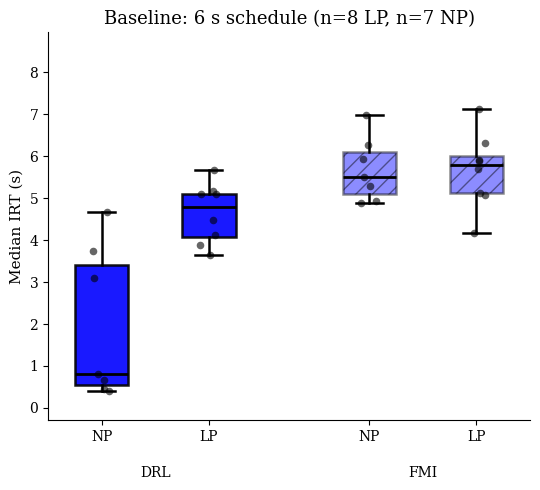

In [86]:
fig, ax = plot_stat_by_schedule(drl_data_lp, drl_data_np, fmi_data_lp, fmi_data_np,
                                 "Baseline", 6, ylabel="Median IRT (s)", tick_interval=1.0)
save_figure(fig, "Baseline_6s_median_IRT_by_schedule")
plt.show()

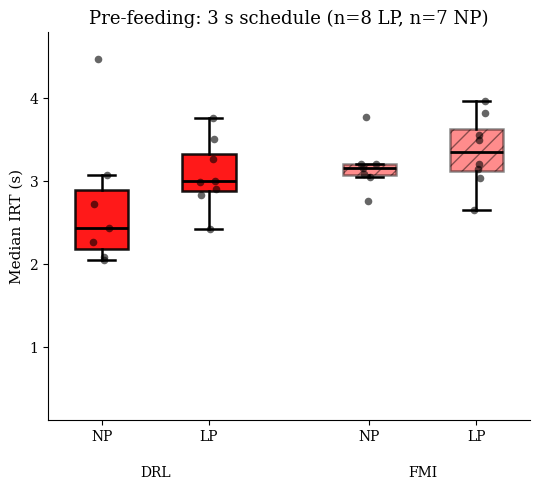

In [87]:
fig, ax = plot_stat_by_schedule(drl_data_lp, drl_data_np, fmi_data_lp, fmi_data_np,
                                 "Pre-feeding", 3, ylabel="Median IRT (s)", tick_interval=1.0)
save_figure(fig, "Prefeeding_3s_median_IRT_by_schedule")
plt.show()

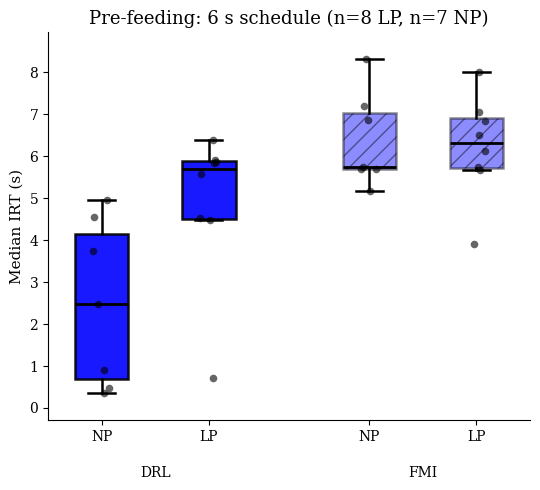

In [88]:
fig, ax = plot_stat_by_schedule(drl_data_lp, drl_data_np, fmi_data_lp, fmi_data_np,
                                 "Pre-feeding", 6, ylabel="Median IRT (s)", tick_interval=1.0)
save_figure(fig, "Prefeeding_6s_median_IRT_by_schedule")
plt.show()

### CQV box plots, arranged by condition: DRL vs. FMI, NP vs. LP

Same arrangement as the Median IRT-by-condition graphs above, plotting CQV instead: 4 graphs (Baseline-3s, Baseline-6s, Pre-feeding-3s, Pre-feeding-6s), each with 4 box plots grouped DRL (NP, LP) and FMI (NP, LP), using the same `plot_stat_by_schedule` function and the CQV data computed earlier (n=8 LP, n=7 NP).

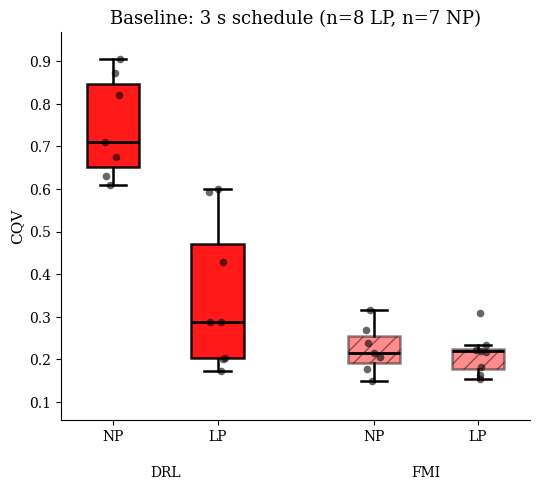

In [89]:
fig, ax = plot_stat_by_schedule(drl_cqv_data_lp, drl_cqv_data_np, fmi_cqv_data_lp, fmi_cqv_data_np,
                                 "Baseline", 3, ylabel="CQV", tick_interval=0.1)
save_figure(fig, "Baseline_3s_CQV_by_schedule")
plt.show()

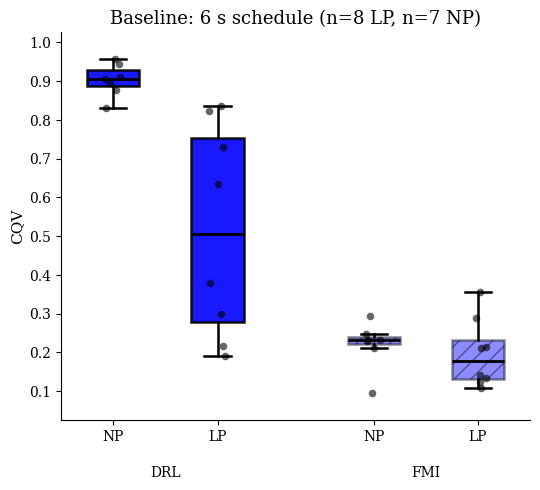

In [90]:
fig, ax = plot_stat_by_schedule(drl_cqv_data_lp, drl_cqv_data_np, fmi_cqv_data_lp, fmi_cqv_data_np,
                                 "Baseline", 6, ylabel="CQV", tick_interval=0.1)
save_figure(fig, "Baseline_6s_CQV_by_schedule")
plt.show()

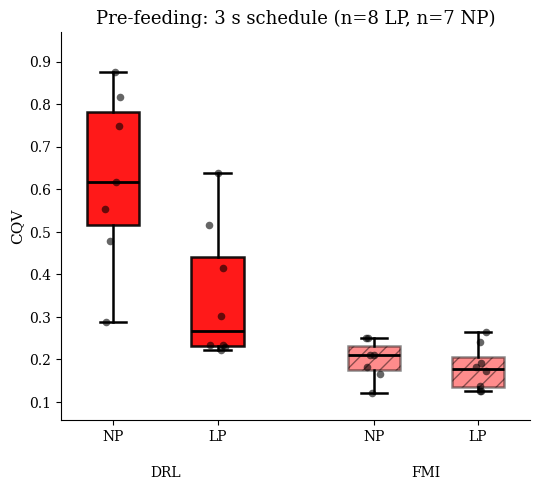

In [91]:
fig, ax = plot_stat_by_schedule(drl_cqv_data_lp, drl_cqv_data_np, fmi_cqv_data_lp, fmi_cqv_data_np,
                                 "Pre-feeding", 3, ylabel="CQV", tick_interval=0.1)
save_figure(fig, "Prefeeding_3s_CQV_by_schedule")
plt.show()

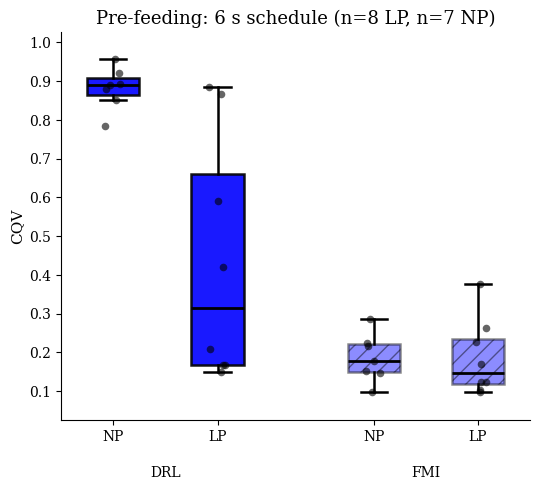

In [92]:
fig, ax = plot_stat_by_schedule(drl_cqv_data_lp, drl_cqv_data_np, fmi_cqv_data_lp, fmi_cqv_data_np,
                                 "Pre-feeding", 6, ylabel="CQV", tick_interval=0.1)
save_figure(fig, "Prefeeding_6s_CQV_by_schedule")
plt.show()

### Median IRT and CQV box plots, arranged by topography group (LP vs. NP)

A third view of the same data: graphs are now split by topography group and wait requirement (LP-3s, NP-3s, LP-6s, NP-6s), 4 graphs each for Median IRT and CQV. Each graph has 4 box plots grouped DRL (Baseline, Pre-feeding) and FMI (Baseline, Pre-feeding).

For the Median IRT graphs, color still marks the wait requirement (red = 3 s, blue = 6 s), and solid/hatched fill distinguishes DRL vs. FMI, matching the other Median IRT graphs.

For the CQV graphs, color instead marks the schedule (DRL = blue, FMI = red), and solid/hatched fill distinguishes Baseline vs. Pre-feeding.

In both cases, the two 3s graphs (LP-3s, NP-3s) share the same y-axis range, and the two 6s graphs (LP-6s, NP-6s) share their own range, so bar heights are directly comparable within each wait requirement.

In [93]:
# --- Median IRT and CQV box plots, arranged by topography group (LP vs NP) ---
GROUP_POSITIONS = [1, 2, 3.5, 4.5]   # DRL-Baseline, DRL-Pre-feeding | FMI-Baseline, FMI-Pre-feeding
GROUP_TICK_LABELS = ["Baseline", "Pre-feeding", "Baseline", "Pre-feeding"]
GROUP_SCHEDULES = ["DRL", "DRL", "FMI", "FMI"]
GROUP_CONDITIONS = ["Baseline", "Pre-feeding", "Baseline", "Pre-feeding"]
SCHEDULE_COLOR = {"DRL": "blue", "FMI": "red"}
GROUP_N = {"LP": 8, "NP": 7}
# A little thicker than the shared box-plot/text defaults, kept local to this panel only.
GROUP_BOX_LINEWIDTH = BOX_LINEWIDTH + 0.6
GROUP_MEDIAN_LINEWIDTH = MEDIAN_LINEWIDTH + 0.6
GROUP_TEXT_STROKE_WIDTH = 0.5
# Subtle per-mouse connecting lines (only meaningful here: all 4 boxes in a by-group panel
# are the same fixed set of mice, unlike the by-schedule/by-condition panels).
CONNECTING_LINE_COLOR = "gray"
CONNECTING_LINE_ALPHA = 0.3
CONNECTING_LINE_WIDTH = 1.0


def plot_stat_by_group(drl_lp_data, drl_np_data, fmi_lp_data, fmi_np_data, group, wait,
                        ylabel="Median IRT (s)", tick_interval=1.0, color_mode="wait",
                        show_connecting_lines=False):
    if group == "LP":
        drl_data, fmi_data = drl_lp_data, fmi_lp_data
    else:
        drl_data, fmi_data = drl_np_data, fmi_np_data

    data = [drl_data["Baseline"][wait], drl_data["Pre-feeding"][wait],
            fmi_data["Baseline"][wait], fmi_data["Pre-feeding"][wait]]

    # Shared y-axis scale across LP and NP for this wait requirement (pooled from both groups)
    all_vals = np.concatenate([
        drl_lp_data["Baseline"][wait], drl_lp_data["Pre-feeding"][wait],
        fmi_lp_data["Baseline"][wait], fmi_lp_data["Pre-feeding"][wait],
        drl_np_data["Baseline"][wait], drl_np_data["Pre-feeding"][wait],
        fmi_np_data["Baseline"][wait], fmi_np_data["Pre-feeding"][wait],
    ])
    y_pad = (all_vals.max() - all_vals.min()) * 0.08
    ylim = (all_vals.min() - y_pad, all_vals.max() + y_pad)

    fig, ax = plt.subplots(figsize=(5.5, 5))
    # Notched, outline-only boxes with a red median and dashed whiskers (MATLAB boxplot style),
    # but keeping our own meaningful colors on the outline instead of a uniform blue.
    bp = ax.boxplot(data, positions=GROUP_POSITIONS, patch_artist=True, widths=0.5, showfliers=False,
                     notch=False,
                     medianprops=dict(color="black", linewidth=GROUP_MEDIAN_LINEWIDTH),
                     whiskerprops=dict(color="black", linewidth=GROUP_BOX_LINEWIDTH, linestyle="--"),
                     capprops=dict(color="black", linewidth=GROUP_BOX_LINEWIDTH))

    for patch, schedule, condition in zip(bp["boxes"], GROUP_SCHEDULES, GROUP_CONDITIONS):
        outline_color = COLOR_WAIT[wait] if color_mode == "wait" else SCHEDULE_COLOR[schedule]
        patch.set_facecolor("white")
        patch.set_edgecolor(outline_color)
        patch.set_linewidth(GROUP_BOX_LINEWIDTH)
        patch.set_alpha(1.0)
        if condition == "Pre-feeding":
            patch.set_hatch("//")

    rng = np.random.default_rng(0)
    jittered_x = []
    for pos, values in zip(GROUP_POSITIONS, data):
        jitter = rng.uniform(-0.08, 0.08, size=len(values))
        x = np.full_like(values, pos) + jitter
        jittered_x.append(x)
        ax.scatter(x, values, s=POINT_SIZE, color=POINT_COLOR,
                   alpha=POINT_ALPHA, zorder=3, linewidths=0)

    if show_connecting_lines:
        # Same mice appear in all 4 boxes of a by-group panel, so connect each mouse's own
        # 4 points (following its exact jittered x-position) across DRL/FMI x Baseline/Pre-feeding.
        n_mice = len(data[0])
        for m in range(n_mice):
            ax.plot([jittered_x[0][m], jittered_x[1][m], jittered_x[2][m], jittered_x[3][m]],
                    [data[0][m], data[1][m], data[2][m], data[3][m]],
                    color=CONNECTING_LINE_COLOR, alpha=CONNECTING_LINE_ALPHA,
                    linewidth=CONNECTING_LINE_WIDTH, zorder=2)

    ax.set_xticks(GROUP_POSITIONS)
    ax.set_xticklabels(GROUP_TICK_LABELS)
    drl_text = ax.text((GROUP_POSITIONS[0] + GROUP_POSITIONS[1]) / 2, -0.12, "DRL",
                        transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=10)
    fmi_text = ax.text((GROUP_POSITIONS[2] + GROUP_POSITIONS[3]) / 2, -0.12, "FMI",
                        transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=10)

    ax.set_ylabel(ylabel)
    ax.set_title(f"{group}: {wait} s schedule (n={GROUP_N[group]} mice)")
    ax.set_ylim(ylim)
    ax.yaxis.set_major_locator(MultipleLocator(tick_interval))
    style_axes(ax)

    # Thicken all the text on this panel a little (title, axis labels, tick labels, DRL/FMI labels)
    text_objects = ([ax.title, ax.xaxis.label, ax.yaxis.label, drl_text, fmi_text]
                     + ax.get_xticklabels() + ax.get_yticklabels())
    for text_obj in text_objects:
        text_obj.set_path_effects([pe.withStroke(linewidth=GROUP_TEXT_STROKE_WIDTH, foreground="black")])

    fig.tight_layout()
    return fig, ax

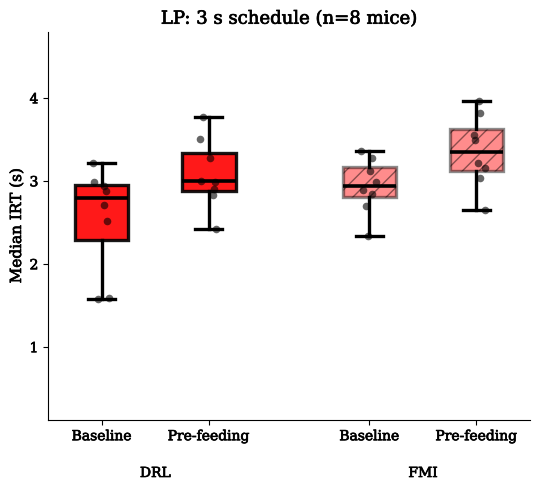

In [94]:
fig, ax = plot_stat_by_group(drl_data_lp, drl_data_np, fmi_data_lp, fmi_data_np,
                              "LP", 3, ylabel="Median IRT (s)", tick_interval=1.0,
                              color_mode="wait", show_connecting_lines=True)
save_figure(fig, "LP_3s_median_IRT_by_group")
plt.show()

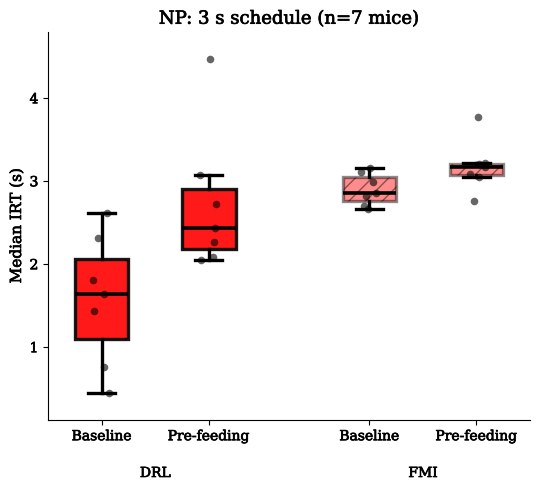

In [95]:
fig, ax = plot_stat_by_group(drl_data_lp, drl_data_np, fmi_data_lp, fmi_data_np,
                              "NP", 3, ylabel="Median IRT (s)", tick_interval=1.0,
                              color_mode="wait", show_connecting_lines=True)
save_figure(fig, "NP_3s_median_IRT_by_group")
plt.show()

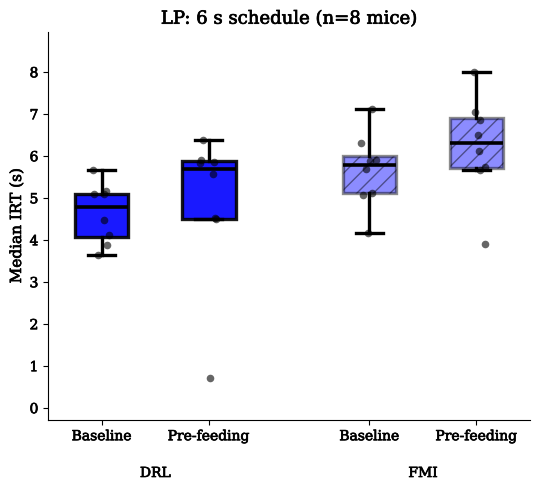

In [96]:
fig, ax = plot_stat_by_group(drl_data_lp, drl_data_np, fmi_data_lp, fmi_data_np,
                              "LP", 6, ylabel="Median IRT (s)", tick_interval=1.0,
                              color_mode="wait", show_connecting_lines=True)
save_figure(fig, "LP_6s_median_IRT_by_group")
plt.show()

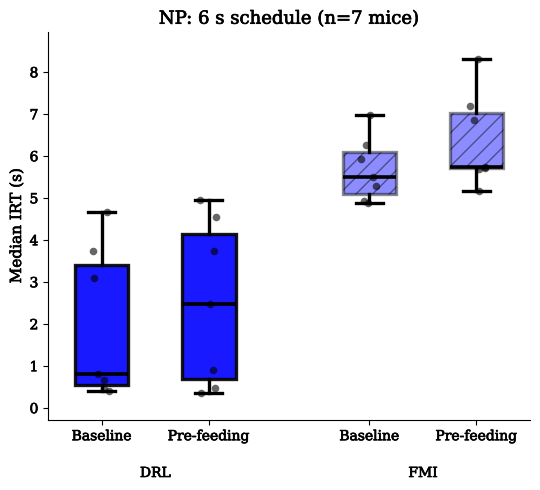

In [97]:
fig, ax = plot_stat_by_group(drl_data_lp, drl_data_np, fmi_data_lp, fmi_data_np,
                              "NP", 6, ylabel="Median IRT (s)", tick_interval=1.0,
                              color_mode="wait", show_connecting_lines=True)
save_figure(fig, "NP_6s_median_IRT_by_group")
plt.show()

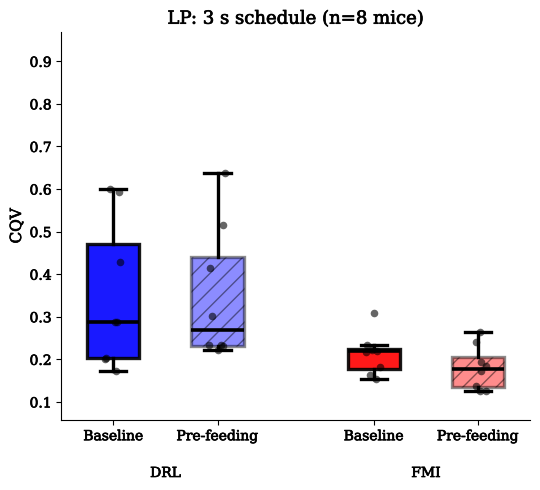

In [98]:
fig, ax = plot_stat_by_group(drl_cqv_data_lp, drl_cqv_data_np, fmi_cqv_data_lp, fmi_cqv_data_np,
                              "LP", 3, ylabel="CQV", tick_interval=0.1,
                              color_mode="schedule")
save_figure(fig, "LP_3s_CQV_by_group")
plt.show()

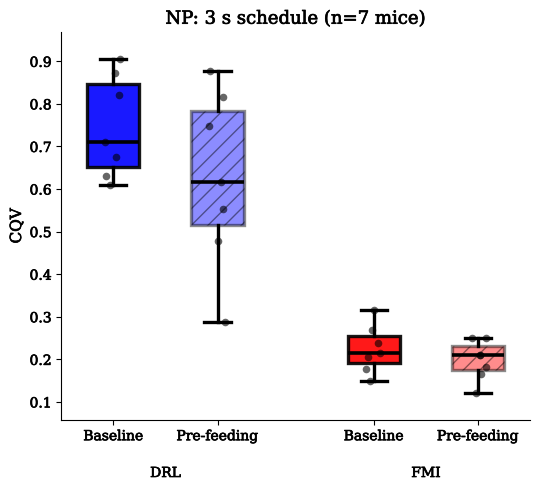

In [99]:
fig, ax = plot_stat_by_group(drl_cqv_data_lp, drl_cqv_data_np, fmi_cqv_data_lp, fmi_cqv_data_np,
                              "NP", 3, ylabel="CQV", tick_interval=0.1,
                              color_mode="schedule")
save_figure(fig, "NP_3s_CQV_by_group")
plt.show()

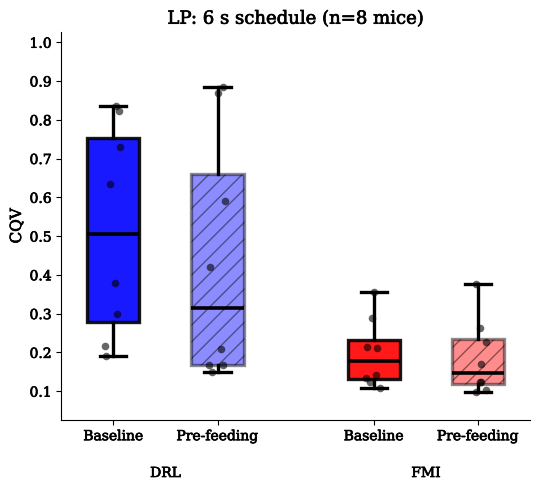

In [100]:
fig, ax = plot_stat_by_group(drl_cqv_data_lp, drl_cqv_data_np, fmi_cqv_data_lp, fmi_cqv_data_np,
                              "LP", 6, ylabel="CQV", tick_interval=0.1,
                              color_mode="schedule")
save_figure(fig, "LP_6s_CQV_by_group")
plt.show()

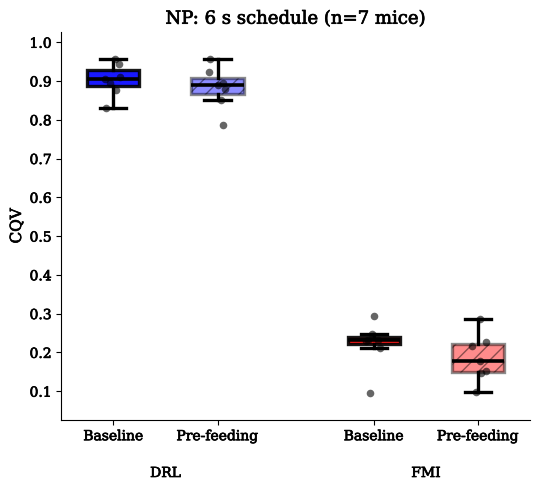

In [101]:
fig, ax = plot_stat_by_group(drl_cqv_data_lp, drl_cqv_data_np, fmi_cqv_data_lp, fmi_cqv_data_np,
                              "NP", 6, ylabel="CQV", tick_interval=0.1,
                              color_mode="schedule")
save_figure(fig, "NP_6s_CQV_by_group")
plt.show()